### SS3 Part B - STADIOalot Order Return Prediction

#### CAP182 - SS3 Part B

This notebook applies the final return-prediction method selected during SS2 to the supplied STADIOalot client data. The final method selected in SS2 was an XGBoost binary classification model. The prediction unit for this stage is an individual order.

The notebook is structured according to the required components:

1. Dataset Loading
2. Dataset Preprocessing
3. Model Training
4. Model Validation
5. Results Visualisation
6. Final Results and Conclusion

### 1. Dataset Loading

The client extract consists of eight related CSV tables covering orders placed between January 2024 and June 2026.
The eight tables are:

1. `table1_orders_transactions.csv`
2. `table2_returns.csv`
3. `table3_product_catalogue.csv`
4. `table4_marketplace_sellers.csv`
5. `table5_customer_information.csv`
6. `table6_customer_behaviour.csv`
7. `table7_inventory_warehouse.csv`
8. `table8_delivery_logistics.csv`

The data is supplied as an uncleaned operational extract in comma-separated values (CSV) format. CSV is suitable for these tabular extracts as it is a widely supported, portable plain-text format that pandas can load directly for inspection, cleaning and analysis. The eight tables are loaded separately first as each represents a different operational subject; they are then checked and joined using the relevant common keys during preprocessing. The agreed prediction unit is an order. An order is labelled as:

- `1` — Returned: at least one return record is associated with the order in the client returns table.
- `0` — Not Returned: no return event is recorded for the order.

The return table is used to construct the target variable however it is not used as a predictive input as its information is only available after the return has occurred.

In [52]:
# ============================================================
# 1. IMPORT LIBRARIES AND CONFIGURE DISPLAY
# ============================================================

import warnings
warnings.filterwarnings("ignore")

from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder
from sklearn.impute import SimpleImputer

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    classification_report,
    roc_curve
)

from xgboost import XGBClassifier

import joblib

# Display settings
pd.set_option("display.max_columns", None)
pd.set_option("display.width", 140)
pd.set_option("display.max_rows", 100)

# Make tables easier to read
pd.set_option("display.float_format", lambda x: f"{x:.2f}")

print("Libraries imported successfully.")
# ============================================================
# 2. SET RANDOM SEED
# ============================================================

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

print(f"Random seed set to: {RANDOM_STATE}")


Libraries imported successfully.
Random seed set to: 42


In [53]:
# ============================================================
# 3. DEFINE CLIENT DATA PATH
# ============================================================

# Locate the project root whether the notebook is run from the project
# root or from the notebooks/ directory.
current_path = Path.cwd().resolve()
PROJECT_ROOT = next(
    (
        folder
        for folder in [current_path, *current_path.parents]
        if folder.name == "STADIOalot-Return-Prediction"
    ),
    None
)

# Fallback: identify the root by its existing project directories.
if PROJECT_ROOT is None:
    PROJECT_ROOT = next(
        (
            folder
            for folder in [current_path, *current_path.parents]
            if (folder / "data" / "raw" / "ClientData").is_dir()
            and (folder / "experimental_results").is_dir()
        ),
        None
    )

if PROJECT_ROOT is None:
    raise FileNotFoundError(
        "Could not locate the STADIOalot-Return-Prediction project root. "
        "Run this notebook from the project root or its notebooks folder."
    )

DATA_PATH = PROJECT_ROOT / "data" / "raw" / "ClientData"

print("PROJECT ROOT:")
print(PROJECT_ROOT.resolve())

print("\nFULL CLIENT DATA DIRECTORY:")
print(DATA_PATH.resolve())


# Define Client Data Files 
client_filenames = [
    "table1_orders_transactions.csv",
    "table2_returns.csv",
    "table3_product_catalogue.csv",
    "table4_marketplace_sellers.csv",
    "table5_customer_information.csv",
    "table6_customer_behaviour.csv",
    "table7_inventory_warehouse.csv",
    "table8_delivery_logistics.csv"
]
# Display filenames and their full directory paths in a table
file_check = pd.DataFrame({
    "Dataset": client_filenames,
    "Full Directory": [
        str((DATA_PATH / filename).resolve())
        for filename in client_filenames
    ],
    "Status": [
        "FOUND" if (DATA_PATH / filename).is_file()
        else "NOT FOUND"
        for filename in client_filenames
    ]
})

print("\nFULL CLIENT DATA DIRECTORY:")
print(DATA_PATH.resolve())



# Client File Check - Display Full Directory Paths 

# Prevent pandas from truncating long directory paths
pd.set_option("display.max_colwidth", None)
pd.set_option("display.max_columns", None)
pd.set_option("display.width", None)

# Build the file-check table
file_check = pd.DataFrame({
    "Dataset": client_filenames,
    "Full Directory": [
        str((DATA_PATH / filename).resolve())
        for filename in client_filenames
    ],
    "Status": [
        "FOUND" if (DATA_PATH / filename).is_file()
        else "NOT FOUND"
        for filename in client_filenames
    ]
})

print("\nCLIENT FILE CHECK:")

# Display the complete paths inside the table
display(file_check)

# Validate Client Data Directory and Files 
if not DATA_PATH.is_dir():
    raise FileNotFoundError(
        f"Client data directory not found: {DATA_PATH.resolve()}"
    )

missing_files = [
    filename for filename in client_filenames
    if not (DATA_PATH / filename).is_file()
]

if missing_files:
    raise FileNotFoundError(
        "The following files could not be found:\n"
        + "\n".join(missing_files)
    )

print("\nAll eight client files have been found.")

# ============================================================
# 4. LOAD ALL EIGHT CLIENT TABLES
# ============================================================
table1_orders = pd.read_csv(DATA_PATH / client_filenames[0])
table2_returns = pd.read_csv(DATA_PATH / client_filenames[1])
table3_products = pd.read_csv(DATA_PATH / client_filenames[2])
table4_sellers = pd.read_csv(DATA_PATH / client_filenames[3])
table5_customers = pd.read_csv(DATA_PATH / client_filenames[4])
table6_behaviour = pd.read_csv(DATA_PATH / client_filenames[5])
table7_inventory = pd.read_csv(DATA_PATH / client_filenames[6])
table8_delivery = pd.read_csv(DATA_PATH / client_filenames[7])

print("\nAll eight client tables loaded successfully.")


# ============================================================
# 5. DISPLAY TABLE STRUCTURE
# ============================================================
tables = {
    "Table 1 - Orders and Transactions": table1_orders,
    "Table 2 - Returns": table2_returns,
    "Table 3 - Product Catalogue": table3_products,
    "Table 4 - Marketplace Sellers": table4_sellers,
    "Table 5 - Customer Information": table5_customers,
    "Table 6 - Customer Behaviour": table6_behaviour,
    "Table 7 - Inventory and Warehouse": table7_inventory,
    "Table 8 - Delivery and Logistics": table8_delivery
}

# Summarise the structure of each client dataset
table_summary = pd.DataFrame([
    {
        "Dataset": name,
        "Rows": len(df),
        "Columns": len(df.columns)
    }
    for name, df in tables.items()
])

print("\nCLIENT DATASET STRUCTURE:")
display(table_summary)

# ============================================================
# 6. DISPLAY COLUMN NAMES IN TABLES
# ============================================================
for name, df in tables.items():

    print(f"\n{name}")

    column_table = pd.DataFrame({
        "Column Number": range(1, len(df.columns) + 1),
        "Column Name": df.columns
    })

    display(column_table)

PROJECT ROOT:
C:\Users\payal\OneDrive - STADIO\2026 Post Graduate Diploma Semester 3\Capstone Project\Assignment\STADIOalot-Return-Prediction

FULL CLIENT DATA DIRECTORY:
C:\Users\payal\OneDrive - STADIO\2026 Post Graduate Diploma Semester 3\Capstone Project\Assignment\STADIOalot-Return-Prediction\data\raw\ClientData

FULL CLIENT DATA DIRECTORY:
C:\Users\payal\OneDrive - STADIO\2026 Post Graduate Diploma Semester 3\Capstone Project\Assignment\STADIOalot-Return-Prediction\data\raw\ClientData

CLIENT FILE CHECK:


,Dataset,Full Directory,Status
0,table1_orders_transactions.csv,C:\Users\payal\OneDrive - STADIO\2026 Post Graduate Diploma Semester 3\Capstone Project\Assignment\STADIOalot-Return-Prediction\data\raw\ClientData\table1_orders_transactions.csv,FOUND
1,table2_returns.csv,C:\Users\payal\OneDrive - STADIO\2026 Post Graduate Diploma Semester 3\Capstone Project\Assignment\STADIOalot-Return-Prediction\data\raw\ClientData\table2_returns.csv,FOUND
2,table3_product_catalogue.csv,C:\Users\payal\OneDrive - STADIO\2026 Post Graduate Diploma Semester 3\Capstone Project\Assignment\STADIOalot-Return-Prediction\data\raw\ClientData\table3_product_catalogue.csv,FOUND
3,table4_marketplace_sellers.csv,C:\Users\payal\OneDrive - STADIO\2026 Post Graduate Diploma Semester 3\Capstone Project\Assignment\STADIOalot-Return-Prediction\data\raw\ClientData\table4_marketplace_sellers.csv,FOUND
4,table5_customer_information.csv,C:\Users\payal\OneDrive - STADIO\2026 Post Graduate Diploma Semester 3\Capstone Project\Assignment\STADIOalot-Return-Prediction\data\raw\ClientData\table5_customer_information.csv,FOUND
5,table6_customer_behaviour.csv,C:\Users\payal\OneDrive - STADIO\2026 Post Graduate Diploma Semester 3\Capstone Project\Assignment\STADIOalot-Return-Prediction\data\raw\ClientData\table6_customer_behaviour.csv,FOUND
6,table7_inventory_warehouse.csv,C:\Users\payal\OneDrive - STADIO\2026 Post Graduate Diploma Semester 3\Capstone Project\Assignment\STADIOalot-Return-Prediction\data\raw\ClientData\table7_inventory_warehouse.csv,FOUND
7,table8_delivery_logistics.csv,C:\Users\payal\OneDrive - STADIO\2026 Post Graduate Diploma Semester 3\Capstone Project\Assignment\STADIOalot-Return-Prediction\data\raw\ClientData\table8_delivery_logistics.csv,FOUND



All eight client files have been found.

All eight client tables loaded successfully.

CLIENT DATASET STRUCTURE:


,Dataset,Rows,Columns
0,Table 1 - Orders and Transactions,11841,11
1,Table 2 - Returns,2037,11
2,Table 3 - Product Catalogue,11818,11
3,Table 4 - Marketplace Sellers,8241,7
4,Table 5 - Customer Information,8241,11
5,Table 6 - Customer Behaviour,8241,9
6,Table 7 - Inventory and Warehouse,11818,7
7,Table 8 - Delivery and Logistics,8241,10



Table 1 - Orders and Transactions


...

,Column Number,Column Name
0,1,order_id
1,2,customer_id
2,3,look_back_period_days
3,4,sessions
4,5,product_views
5,6,add_to_basket_count
6,7,previous_orders
7,8,previous_returns
8,9,customer_return_rate



Table 7 - Inventory and Warehouse


,Column Number,Column Name
0,1,order_id
1,2,sku
2,3,distribution_centre
3,4,stock_on_hand
4,5,stock_age_days
5,6,historical_pick_pack_time
6,7,inbound_datetime



Table 8 - Delivery and Logistics


,Column Number,Column Name
0,1,order_id
1,2,estimated_delivery_datetime
2,3,delivery_option
3,4,delivery_province
4,5,route_distance_km
5,6,historical_delivery_time_days
6,7,historical_delivery_failure_rate
7,8,actual_delivery_datetime
8,9,delivery_attempts
9,10,on_time_flag


In [54]:
# ============================================================
# 7. CREATE ORDER-LEVEL TARGET
# ============================================================

# Obtain the distinct list of orders from the main order table.
orders = table1_orders[["order_id"]].drop_duplicates().copy()

# Identify orders with at least one return
returned_orders = (
    table2_returns[["order_id"]]
    .drop_duplicates()
    .assign(Return_Status=1)
)

# Left join returns onto all orders
orders_with_target = orders.merge(
    returned_orders,
    on="order_id",
    how="left"
)

# Orders without a return record are classified as 0.
orders_with_target["Return_Status"] = (
    orders_with_target["Return_Status"]
    .fillna(0)
    .astype(int)
)

print("Order-level target created successfully.")
print(f"Total unique orders: {len(orders_with_target):,}")

Order-level target created successfully.
Total unique orders: 8,241


In [55]:
# ============================================================
# 8. CLASS DISTRIBUTION AND CLASS IMBALANCE
# ============================================================

# Calculate class counts
class_counts = (
    orders_with_target["Return_Status"]
    .value_counts()
    .sort_index()
)

# Calculate class percentages
class_percentages = (
    orders_with_target["Return_Status"]
    .value_counts(normalize=True)
    .sort_index()
    * 100
)

# Extract class counts
not_returned = class_counts.get(0, 0)
returned = class_counts.get(1, 0)

# Calculate imbalance ratio
if returned > 0:
    imbalance_ratio = not_returned / returned
else:
    imbalance_ratio = np.nan

# Create combined summary table
class_summary = pd.DataFrame({
    "Class": [
        "0 - Not Returned",
        "1 - Returned",
        "Class Imbalance"
    ],
    "Count": [
        not_returned,
        returned,
        np.nan
    ],
    "Percentage": [
        class_percentages.get(0, 0),
        class_percentages.get(1, 0),
        np.nan
    ],
    "Imbalance Ratio": [
        np.nan,
        np.nan,
        imbalance_ratio
    ]
})

# Display combined table
print("\nCLASS DISTRIBUTION AND IMBALANCE SUMMARY:")

display(
    class_summary.style
    .format({
        "Count": lambda x: f"{x:,.0f}" if pd.notna(x) else "—",
        "Percentage": lambda x: f"{x:.2f}%" if pd.notna(x) else "—",
        "Imbalance Ratio": lambda x: f"{x:.2f}:1" if pd.notna(x) else "—"
    })
    .hide(axis="index")
    .set_caption("Order-Level Target Distribution and Class Imbalance")
)


CLASS DISTRIBUTION AND IMBALANCE SUMMARY:


Class,Count,Percentage,Imbalance Ratio
0 - Not Returned,"6,372",77.32%,—
1 - Returned,"1,869",22.68%,—
Class Imbalance,—,—,3.41:1


### Dataset Loading Summary

The eight client tables have been loaded separately as they contain different types of information linked through keys such as `order_id`, `customer_id`, `seller_id` and `sku`. The modelling dataset contains **8,241 unique orders**, with one row per order, as the business question is to predict whether an order will result in a return.

The target variable is `Return_Status`:

- **Class 0 — Not Returned:** 6,372 orders (**77.32%**).
- **Class 1 — Returned:** 1,869 orders (**22.68%**).

The class imbalance ratio is approximately **3.41:1** (not-returned to returned orders). Returned orders are therefore the minority class. This matters when interpreting performance as a model can achieve seemingly high accuracy by mostly predicting the majority class; precision, recall, F1-score and ROC-AUC are also reported.

**Format justification:** CSV is appropriate for the supplied structured tables as it preserves rows and columns in a portable format and can be read directly by `pandas.read_csv()`. Loading each file separately also allows columns, data types, missing values and join keys to be checked before the tables are combined.

**Target construction:** `table2_returns.csv` is used to identify orders with a return record and construct `Return_Status`; it is not used as a predictive input as it contains information about the outcome itself.

### 2. Dataset Preprocessing

The supplied client extract is not pre-cleaned. Therefore, preprocessing is required before model training.
The preprocessing stage performs the following tasks:

1. Standardise column data types where required.
2. Convert date and datetime fields into usable representations.
3. Construct the order-level target.
4. Aggregate item-level tables to one row per order.
5. Combine the eight data sources using their agreed keys.
6. Remove identifiers that should not be used as predictive features.
7. Remove information that becomes available only after the prediction point.
8. Create useful order-level temporal and numerical features.
9. Handle missing numerical and categorical values.
10. Encode categorical variables.
11. Split the data into training, validation and unseen test subsets.

The prediction point is at the order stage. Therefore, only information available at or before the order timestamp is retained as a predictor. `table2_returns.csv` is used to construct the target however is not used as a predictor. In `table8_delivery_logistics.csv`, `actual_delivery_datetime`, `delivery_attempts` and `on_time_flag` are excluded as they are post-purchase information.

In [56]:
# ============================================================
# 9. STANDARDISE IMPORTANT DATA TYPES
# ============================================================

# ------------------------------------------------------------
# Orders
# ------------------------------------------------------------
table1_orders["order_datetime"] = pd.to_datetime(
    table1_orders["order_datetime"],
    errors="coerce"
)

table1_orders["quantity"] = pd.to_numeric(
    table1_orders["quantity"],
    errors="coerce"
)

table1_orders["unit_price"] = pd.to_numeric(
    table1_orders["unit_price"],
    errors="coerce"
)

table1_orders["promotion_amount"] = pd.to_numeric(
    table1_orders["promotion_amount"],
    errors="coerce"
)

# ------------------------------------------------------------
# Product catalogue
# ------------------------------------------------------------
for column in [
    "product_price",
    "product_rating",
    "review_count",
    "listing_age_days"
]:
    table3_products[column] = pd.to_numeric(
        table3_products[column],
        errors="coerce"
    )

# ------------------------------------------------------------
# Marketplace sellers
# ------------------------------------------------------------
for column in [
    "seller_rating",
    "seller_tenure_months",
    "average_shipping_days",
    "late_shipment_rate",
    "complaint_count"
]:
    table4_sellers[column] = pd.to_numeric(
        table4_sellers[column],
        errors="coerce"
    )

# ------------------------------------------------------------
# Customer information
# ------------------------------------------------------------
for column in [
    "customer_age",
    "customer_tenure_months",
    "average_order_value",
    "total_historical_spend",
    "previous_returned_orders"
]:
    table5_customers[column] = pd.to_numeric(
        table5_customers[column],
        errors="coerce"
    )

# ------------------------------------------------------------
# Customer behaviour
# ------------------------------------------------------------
for column in [
    "look_back_period_days",
    "sessions",
    "product_views",
    "add_to_basket_count",
    "previous_orders",
    "previous_returns",
    "customer_return_rate"
]:
    table6_behaviour[column] = pd.to_numeric(
        table6_behaviour[column],
        errors="coerce"
    )

# ------------------------------------------------------------
# Inventory
# ------------------------------------------------------------
for column in [
    "stock_on_hand",
    "stock_age_days",
    "historical_pick_pack_time"
]:
    table7_inventory[column] = pd.to_numeric(
        table7_inventory[column],
        errors="coerce"
    )

# ------------------------------------------------------------
# Delivery
# ------------------------------------------------------------
for column in [
    "route_distance_km",
    "historical_delivery_time_days",
    "historical_delivery_failure_rate"
]:
    table8_delivery[column] = pd.to_numeric(
        table8_delivery[column],
        errors="coerce"
    )

print("Important data types standardised.")

Important data types standardised.


In [57]:
# ============================================================
# 10. DATA QUALITY CHECKS
# ============================================================

def data_quality_summary(df, table_name):
    summary = pd.DataFrame({
        "Column": df.columns,
        "Data Type": df.dtypes.astype(str).values,
        "Missing Values": df.isna().sum().values,
        "Missing %": (
            df.isna().mean().values * 100
        ),
        "Unique Values": [
            df[col].nunique(dropna=True)
            for col in df.columns
        ]
    })

    display(
        summary.style
        .format({"Missing %": "{:.2f}%"})
        .set_caption(f"Data Quality — {table_name}")
    )

for name, df in tables.items():
    data_quality_summary(df, name)

,Column,Data Type,Missing Values,Missing %,Unique Values
0,order_id,str,0,0.00%,8241
1,customer_id,str,0,0.00%,4092
2,order_datetime,datetime64[us],126,1.06%,8179
3,sku,str,0,0.00%,1204
4,seller_id,str,0,0.00%,147
5,quantity,int64,0,0.00%,3
6,unit_price,float64,0,0.00%,1215
7,promotion_amount,float64,0,0.00%,3003
8,payment_method,str,0,0.00%,25
9,delivery_option,str,0,0.00%,20


,Column,Data Type,Missing Values,Missing %,Unique Values
0,return_id,str,0,0.00%,2037
1,order_id,str,0,0.00%,1869
2,return_datetime,str,0,0.00%,2037
3,return_receipt_datetime,str,0,0.00%,2037
4,returned_quantity,int64,0,0.00%,3
5,return_reason,str,0,0.00%,20
6,return_condition,str,0,0.00%,14
7,refund_amount,float64,0,0.00%,2030
8,refund_outcome,str,0,0.00%,5
9,return_cost,float64,0,0.00%,1882


,Column,Data Type,Missing Values,Missing %,Unique Values
0,order_id,str,0,0.00%,8241
1,sku,str,0,0.00%,1204
2,product_category,str,0,0.00%,41
3,subcategory,str,0,0.00%,142
4,brand,str,0,0.00%,20
5,size,str,7049,59.65%,16
6,colour,str,0,0.00%,55
7,product_price,float64,0,0.00%,1194
8,product_rating,float64,480,4.06%,35
9,review_count,int64,0,0.00%,1100


,Column,Data Type,Missing Values,Missing %,Unique Values
0,order_id,str,0,0.00%,8241
1,seller_id,str,0,0.00%,147
2,seller_rating,float64,0,0.00%,22
3,seller_tenure_months,int64,0,0.00%,97
4,average_shipping_days,float64,0,0.00%,39
5,late_shipment_rate,float64,0,0.00%,107
6,complaint_count,int64,0,0.00%,44


,Column,Data Type,Missing Values,Missing %,Unique Values
0,order_id,str,0,0.00%,8241
1,customer_id,str,0,0.00%,4092
2,customer_age,float64,47,0.57%,61
3,customer_gender,str,0,0.00%,15
4,customer_province,str,0,0.00%,24
5,account_creation_date,str,0,0.00%,4092
6,customer_tenure_months,int64,0,0.00%,78
7,preferred_shopping_channel,str,0,0.00%,15
8,average_order_value,float64,4092,49.65%,3769
9,total_historical_spend,float64,0,0.00%,3776


,Column,Data Type,Missing Values,Missing %,Unique Values
0,order_id,str,0,0.00%,8241
1,customer_id,str,0,0.00%,4092
2,look_back_period_days,int64,0,0.00%,1
3,sessions,int64,0,0.00%,27
4,product_views,int64,0,0.00%,152
5,add_to_basket_count,int64,0,0.00%,21
6,previous_orders,int64,0,0.00%,7
7,previous_returns,int64,0,0.00%,6
8,customer_return_rate,float64,0,0.00%,12


,Column,Data Type,Missing Values,Missing %,Unique Values
0,order_id,str,0,0.00%,8241
1,sku,str,0,0.00%,1204
2,distribution_centre,str,0,0.00%,5
3,stock_on_hand,int64,0,0.00%,584
4,stock_age_days,int64,0,0.00%,196
5,historical_pick_pack_time,float64,0,0.00%,166
6,inbound_datetime,str,0,0.00%,11818


,Column,Data Type,Missing Values,Missing %,Unique Values
0,order_id,str,0,0.00%,8241
1,estimated_delivery_datetime,str,0,0.00%,8239
2,delivery_option,str,0,0.00%,5
3,delivery_province,str,0,0.00%,9
4,route_distance_km,float64,0,0.00%,675
5,historical_delivery_time_days,float64,0,0.00%,57
6,historical_delivery_failure_rate,float64,0,0.00%,85
7,actual_delivery_datetime,str,0,0.00%,8241
8,delivery_attempts,int64,0,0.00%,2
9,on_time_flag,int64,0,0.00%,2


In [58]:
# ============================================================
# 11. AGGREGATE TABLE 1 — ORDERS AND TRANSACTIONS
# ============================================================

# Create line-level monetary value first.
table1_orders["line_gross_value"] = (
    table1_orders["quantity"] *
    table1_orders["unit_price"]
)

table1_orders["net_line_value"] = (
    table1_orders["line_gross_value"]
    - table1_orders["promotion_amount"].fillna(0)
)


# Aggregate item-level information to one row per order.
orders_features = (
    table1_orders
    .groupby("order_id", as_index=False)
    .agg(
        customer_id=("customer_id", "first"),
        order_datetime=("order_datetime", "first"),

        item_count=("sku", "nunique"),
        total_quantity=("quantity", "sum"),

        order_gross_value=("line_gross_value", "sum"),
        total_promotion_amount=("promotion_amount", "sum"),
        order_net_value=("net_line_value", "sum"),

        average_unit_price=("unit_price", "mean"),

        payment_method=("payment_method", "first"),
        delivery_option=("delivery_option", "first"),
        customer_province=("customer_province", "first")
    )
)


print("Table 1 aggregated to order level.")
print(f"Orders represented: {len(orders_features):,}")

print("\nDisplay Orders Features")
display(orders_features.head())

# ============================================================
# 12. AGGREGATE TABLE 3 — PRODUCT CATALOGUE
# ============================================================

products_features = (
    table3_products
    .groupby("order_id", as_index=False)
    .agg(
        average_product_price=("product_price", "mean"),
        average_product_rating=("product_rating", "mean"),
        average_review_count=("review_count", "mean"),
        average_listing_age_days=("listing_age_days", "mean"),

        product_category=("product_category", "first"),
        product_subcategory=("subcategory", "first"),
        product_brand=("brand", "first"),
        product_size=("size", "first"),
        product_colour=("colour", "first")
    )
)


print("Table 3 aggregated to order level.")
print(f"Orders represented: {len(products_features):,}")

print("\nDisplay Products Features")
display(products_features.head())

# ============================================================
# 13. AGGREGATE TABLE 7 — INVENTORY AND WAREHOUSE
# ============================================================

inventory_features = (
    table7_inventory
    .groupby("order_id", as_index=False)
    .agg(
        average_stock_on_hand=("stock_on_hand", "mean"),
        minimum_stock_on_hand=("stock_on_hand", "min"),

        average_stock_age_days=("stock_age_days", "mean"),

        average_pick_pack_time=("historical_pick_pack_time", "mean"),

        distribution_centre=("distribution_centre", "first")
    )
)


print("Table 7 aggregated to order level.")
print(f"Orders represented: {len(inventory_features):,}")

print("\nDisplay Inventory Features")
display(inventory_features.head())

# ============================================================
# 14. AGGREGATE TABLE 4 — MARKETPLACE SELLERS
# ============================================================

seller_features = (
    table4_sellers
    .groupby("order_id", as_index=False)
    .agg(
        average_seller_rating=("seller_rating", "mean"),
        average_seller_tenure_months=("seller_tenure_months", "mean"),
        average_shipping_days=("average_shipping_days", "mean"),
        average_late_shipment_rate=("late_shipment_rate", "mean"),
        total_seller_complaints=("complaint_count", "sum")
    )
)

print("Display Seller Features")
display(seller_features.head())

Table 1 aggregated to order level.
Orders represented: 8,241

Display Orders Features


,order_id,customer_id,order_datetime,item_count,total_quantity,order_gross_value,total_promotion_amount,order_net_value,average_unit_price,payment_method,delivery_option,customer_province
0,ORD840000,CUST20997,2026-01-06 09:07:48,1,3,816.42,0.00,816.42,272.14,Instant EFT,Standard,WC
1,ORD840001,CUST20407,2026-05-06 02:04:40,1,1,56.47,0.00,56.47,56.47,Instant EFT,Express,GP
2,ORD840002,CUST20793,2026-04-23 22:55:50,2,2,623.78,83.61,540.17,311.89,Wallet,Express,WC
3,ORD840003,CUST21163,2024-01-16 16:01:57,4,4,1545.93,344.97,1200.96,386.48,Card,Standard,GP
4,ORD840004,CUST20008,2024-06-14 07:53:53,1,1,864.55,0.00,864.55,864.55,Card,Express,FS


Table 3 aggregated to order level.
Orders represented: 8,241

Display Products Features


,order_id,average_product_price,average_product_rating,average_review_count,average_listing_age_days,product_category,product_subcategory,product_brand,product_size,product_colour
0,ORD840000,272.14,3.60,9.00,751.00,Baby & Kids,Nursery,Brand Q,S,Green
1,ORD840001,56.47,3.00,117.00,414.00,Baby & Kids,Feeding,Brand R,XXL,Olive
2,ORD840002,311.89,3.55,855.50,1082.50,Toys & Games,Outdoor Toys,Brand G,XS,Cream
3,ORD840003,386.48,3.83,0.00,0.00,Apparel,Women's Dresses,Brand C,XXL,Navy
4,ORD840004,864.55,3.60,256.00,823.00,Home & Kitchen,Lighting,Brand Q,NaN,Blue


Table 7 aggregated to order level.
Orders represented: 8,241

Display Inventory Features


,order_id,average_stock_on_hand,minimum_stock_on_hand,average_stock_age_days,average_pick_pack_time,distribution_centre
0,ORD840000,437.00,437,20.00,5.60,DC1
1,ORD840001,192.00,192,23.00,10.00,DC3
2,ORD840002,162.00,64,49.00,8.40,DC5
3,ORD840003,179.75,19,43.50,6.50,DC4
4,ORD840004,305.00,305,29.00,11.30,DC4


Display Seller Features


,order_id,average_seller_rating,average_seller_tenure_months,average_shipping_days,average_late_shipment_rate,total_seller_complaints
0,ORD840000,3.80,19.00,3.50,0.13,18
1,ORD840001,4.10,35.00,3.70,0.12,10
2,ORD840002,3.90,60.00,3.40,0.11,15
3,ORD840003,4.20,29.00,3.50,0.12,7
4,ORD840004,3.70,27.00,4.00,0.14,7


In [59]:
# ============================================================
# 15. TABLE 5 — CUSTOMER INFORMATION
# ============================================================

customer_features = (
    table5_customers
    .drop_duplicates(subset=["order_id"])
    .copy()
)


customer_features = customer_features[
    [
        "order_id",
        "customer_age",
        "customer_gender",
        "customer_province",
        "account_creation_date",
        "customer_tenure_months",
        "preferred_shopping_channel",
        "average_order_value",
        "total_historical_spend",
        "previous_returned_orders"
    ]
]


customer_features["account_creation_date"] = pd.to_datetime(
    customer_features["account_creation_date"],
    errors="coerce"
)

print("Display Customer Features")
display(customer_features.head())

# ============================================================
# 16. TABLE 6 — CUSTOMER BEHAVIOUR
# ============================================================

behaviour_features = (
    table6_behaviour
    .drop_duplicates(subset=["order_id"])
    .copy()
)


behaviour_features = behaviour_features[
    [
        "order_id",
        "look_back_period_days",
        "sessions",
        "product_views",
        "add_to_basket_count",
        "previous_orders",
        "previous_returns",
        "customer_return_rate"
    ]
]

print("Display Customer Behaviour")
display(behaviour_features.head())

# ============================================================
# 17. TABLE 8 — DELIVERY AND LOGISTICS
# ============================================================

delivery_features = (
    table8_delivery
    .drop_duplicates(subset=["order_id"])
    .copy()
)

# Convert dates.
delivery_features["estimated_delivery_datetime"] = pd.to_datetime(
    delivery_features["estimated_delivery_datetime"],
    errors="coerce"
)

delivery_features["actual_delivery_datetime"] = pd.to_datetime(
    delivery_features["actual_delivery_datetime"],
    errors="coerce"
)


# Keep only pre-purchase delivery information.
delivery_features = delivery_features[
    [
        "order_id",
        "estimated_delivery_datetime",
        "delivery_option",
        "delivery_province",
        "route_distance_km",
        "historical_delivery_time_days",
        "historical_delivery_failure_rate"
    ]
].copy()

print("Display Delivery Features")
display(delivery_features.head())

Display Customer Features


,order_id,customer_age,customer_gender,customer_province,account_creation_date,customer_tenure_months,preferred_shopping_channel,average_order_value,total_historical_spend,previous_returned_orders
0,ORD840000,35.00,Male,WC,2025-12-13 22:41:13,0,Mobile App,NaN,0.00,0
1,ORD840001,41.00,Female,GP,2020-10-06 02:11:44,66,Website,NaN,0.00,0
2,ORD840002,30.00,Other,WC,2020-12-03 09:54:40,64,Mobile App,NaN,0.00,0
3,ORD840003,67.00,Female,GP,2021-06-06 06:11:24,31,Website,NaN,0.00,0
4,ORD840004,39.00,Male,FS,2022-10-18 22:09:09,19,Website,NaN,0.00,0


Display Customer Behaviour


,order_id,look_back_period_days,sessions,product_views,add_to_basket_count,previous_orders,previous_returns,customer_return_rate
0,ORD840000,30,0,37,4,0,0,0.00
1,ORD840001,30,4,25,2,0,0,0.00
2,ORD840002,30,3,31,12,0,0,0.00
3,ORD840003,30,3,40,5,0,0,0.00
4,ORD840004,30,6,106,6,0,0,0.00


Display Delivery Features


,order_id,estimated_delivery_datetime,delivery_option,delivery_province,route_distance_km,historical_delivery_time_days,historical_delivery_failure_rate
0,ORD840000,2026-01-10 18:41:52,Standard,WC,33.40,2.20,0.11
1,ORD840001,2026-05-08 12:04:19,Express,GP,6.00,3.30,0.09
2,ORD840002,2026-04-26 13:40:05,Express,WC,25.70,1.40,0.07
3,ORD840003,2024-01-22 00:06:50,Standard,GP,5.00,2.80,0.12
4,ORD840004,2024-06-17 06:47:23,Express,FS,40.10,4.70,0.09


In [60]:
# ============================================================
# 18. MERGE ALL PREDICTIVE TABLES
# ============================================================

model_data = orders_features.copy()

# Product information
model_data = model_data.merge(
    products_features,
    on="order_id",
    how="left"
)

# Seller information
model_data = model_data.merge(
    seller_features,
    on="order_id",
    how="left"
)

# Customer information
model_data = model_data.merge(
    customer_features,
    on="order_id",
    how="left"
)

# Customer behaviour
model_data = model_data.merge(
    behaviour_features,
    on="order_id",
    how="left"
)

# Inventory information
model_data = model_data.merge(
    inventory_features,
    on="order_id",
    how="left"
)

# Delivery information
model_data = model_data.merge(
    delivery_features,
    on="order_id",
    how="left"
)

# Add target.
model_data = model_data.merge(
    orders_with_target,
    on="order_id",
    how="left"
)

print(f"Final modelling rows before feature preparation: {len(model_data):,}")
print(f"Final modelling columns: {len(model_data.columns):,}")

display(model_data.head())

# ============================================================
# 19. VERIFY ORDER-LEVEL MODELLING UNIT
# ============================================================

total_rows = len(model_data)
unique_orders = model_data["order_id"].nunique()

print(f"Total modelling rows : {total_rows:,}")
print(f"Unique order IDs     : {unique_orders:,}")

if total_rows == unique_orders:
    print("\nPASS: There is exactly one modelling row per order.")
else:
    print("\nWARNING: Duplicate order IDs remain.")

Final modelling rows before feature preparation: 8,241
Final modelling columns: 54


,order_id,customer_id,order_datetime,item_count,total_quantity,order_gross_value,total_promotion_amount,order_net_value,average_unit_price,payment_method,delivery_option_x,customer_province_x,average_product_price,average_product_rating,average_review_count,average_listing_age_days,product_category,product_subcategory,product_brand,product_size,product_colour,average_seller_rating,average_seller_tenure_months,average_shipping_days,average_late_shipment_rate,total_seller_complaints,customer_age,customer_gender,customer_province_y,account_creation_date,customer_tenure_months,preferred_shopping_channel,average_order_value,total_historical_spend,previous_returned_orders,look_back_period_days,sessions,product_views,add_to_basket_count,previous_orders,previous_returns,customer_return_rate,average_stock_on_hand,minimum_stock_on_hand,average_stock_age_days,average_pick_pack_time,distribution_centre,estimated_delivery_datetime,delivery_option_y,delivery_province,route_distance_km,historical_delivery_time_days,historical_delivery_failure_rate,Return_Status
0,ORD840000,CUST20997,2026-01-06 09:07:48,1,3,816.42,0.00,816.42,272.14,Instant EFT,Standard,WC,272.14,3.60,9.00,751.00,Baby & Kids,Nursery,Brand Q,S,Green,3.80,19.00,3.50,0.13,18,35.00,Male,WC,2025-12-13 22:41:13,0,Mobile App,NaN,0.00,0,30,0,37,4,0,0,0.00,437.00,437,20.00,5.60,DC1,2026-01-10 18:41:52,Standard,WC,33.40,2.20,0.11,0
1,ORD840001,CUST20407,2026-05-06 02:04:40,1,1,56.47,0.00,56.47,56.47,Instant EFT,Express,GP,56.47,3.00,117.00,414.00,Baby & Kids,Feeding,Brand R,XXL,Olive,4.10,35.00,3.70,0.12,10,41.00,Female,GP,2020-10-06 02:11:44,66,Website,NaN,0.00,0,30,4,25,2,0,0,0.00,192.00,192,23.00,10.00,DC3,2026-05-08 12:04:19,Express,GP,6.00,3.30,0.09,1
2,ORD840002,CUST20793,2026-04-23 22:55:50,2,2,623.78,83.61,540.17,311.89,Wallet,Express,WC,311.89,3.55,855.50,1082.50,Toys & Games,Outdoor Toys,Brand G,XS,Cream,3.90,60.00,3.40,0.11,15,30.00,Other,WC,2020-12-03 09:54:40,64,Mobile App,NaN,0.00,0,30,3,31,12,0,0,0.00,162.00,64,49.00,8.40,DC5,2026-04-26 13:40:05,Express,WC,25.70,1.40,0.07,0
3,ORD840003,CUST21163,2024-01-16 16:01:57,4,4,1545.93,344.97,1200.96,386.48,Card,Standard,GP,386.48,3.83,0.00,0.00,Apparel,Women's Dresses,Brand C,XXL,Navy,4.20,29.00,3.50,0.12,7,67.00,Female,GP,2021-06-06 06:11:24,31,Website,NaN,0.00,0,30,3,40,5,0,0,0.00,179.75,19,43.50,6.50,DC4,2024-01-22 00:06:50,Standard,GP,5.00,2.80,0.12,0
4,ORD840004,CUST20008,2024-06-14 07:53:53,1,1,864.55,0.00,864.55,864.55,Card,Express,FS,864.55,3.60,256.00,823.00,Home & Kitchen,Lighting,Brand Q,NaN,Blue,3.70,27.00,4.00,0.14,7,39.00,Male,FS,2022-10-18 22:09:09,19,Website,NaN,0.00,0,30,6,106,6,0,0,0.00,305.00,305,29.00,11.30,DC4,2024-06-17 06:47:23,Express,FS,40.10,4.70,0.09,0


Total modelling rows : 8,241
Unique order IDs     : 8,241

PASS: There is exactly one modelling row per order.


In [61]:
# ============================================================
# 20. ORDER-LEVEL FEATURE ENGINEERING
# ============================================================

# Order date features
model_data["order_year"] = (
    model_data["order_datetime"].dt.year
)

model_data["order_month"] = (
    model_data["order_datetime"].dt.month
)

model_data["order_day"] = (
    model_data["order_datetime"].dt.day
)

model_data["order_day_of_week"] = (
    model_data["order_datetime"].dt.dayofweek
)

model_data["order_week_of_year"] = (
    model_data["order_datetime"].dt.isocalendar().week.astype("float")
)

model_data["is_weekend"] = (
    model_data["order_day_of_week"] >= 5
).astype(int)

# Estimated delivery lead time
model_data["estimated_delivery_days"] = (
    (
        model_data["estimated_delivery_datetime"]
        - model_data["order_datetime"]
    )
    .dt.total_seconds()
    / (24 * 60 * 60)
)

# Discount-related feature
model_data["discount_fraction"] = np.where(
    model_data["order_gross_value"] > 0,
    model_data["total_promotion_amount"] /
    model_data["order_gross_value"],
    0
)

model_data["discount_fraction"] = (
    model_data["discount_fraction"]
    .clip(lower=0, upper=1)
)

print("Feature engineering completed.")

Feature engineering completed.


In [62]:
# ============================================================
# 21. REMOVE IDENTIFIERS AND POST-PURCHASE INFORMATION
# ============================================================

# These fields are identifiers rather than predictive characteristics.
identifier_columns = [
    "order_id",
    "customer_id"
]

# These fields are dates/timestamps represented by engineered features.
raw_datetime_columns = [
    "order_datetime",
    "account_creation_date",
    "estimated_delivery_datetime"
]

# Post-purchase delivery information.
# These must not be available to the model as they occur after the prediction point.
post_purchase_columns = [
    "actual_delivery_datetime",
    "delivery_attempts",
    "on_time_flag"
]

columns_to_drop = (
    identifier_columns
    + raw_datetime_columns
    + post_purchase_columns
)

# Only drop columns that exist.
columns_to_drop = [
    column
    for column in columns_to_drop
    if column in model_data.columns
]

model_data = model_data.drop(
    columns=columns_to_drop
)

print("Removed columns:")
for column in columns_to_drop:
    print(f" - {column}")

Removed columns:
 - order_id
 - customer_id
 - order_datetime
 - account_creation_date
 - estimated_delivery_datetime


In [63]:
# ============================================================
# 22. FINAL FEATURE TABLE
# ============================================================

X = model_data.drop(
    columns=["Return_Status"]
)

y = model_data["Return_Status"].astype(int)

# ------------------------------------------------------------
# Table 1: Final Feature Table Summary
# ------------------------------------------------------------

feature_summary = pd.DataFrame({
    "Metric": [
        "Number of observations",
        "Number of predictor variables"
    ],
    "Value": [
        f"{len(X):,}",
        f"{X.shape[1]:,}"
    ]
})

print("\nFINAL FEATURE TABLE SUMMARY:")
display(feature_summary)

# ------------------------------------------------------------
# Table 2: Target Distribution
# ------------------------------------------------------------

target_distribution = (
    y.value_counts()
    .sort_index()
    .rename_axis("Return_Status")
    .reset_index(name="Count")
)

target_distribution["Return_Status"] = (
    target_distribution["Return_Status"]
    .map({
        0: "0 - Not Returned",
        1: "1 - Returned"
    })
)

target_distribution["Percentage"] = (
    target_distribution["Count"]
    / target_distribution["Count"].sum()
    * 100
)

print("\nTARGET DISTRIBUTION:")

display(
    target_distribution.style
    .format({
        "Count": "{:,}",
        "Percentage": "{:.2f}%"
    })
    .hide(axis="index")
)


FINAL FEATURE TABLE SUMMARY:


,Metric,Value
0,Number of observations,"8,241"
1,Number of predictor variables,56



TARGET DISTRIBUTION:


Return_Status,Count,Percentage
0 - Not Returned,"6,372",77.32%
1 - Returned,"1,869",22.68%


In [64]:
# ============================================================
# 23. IDENTIFY NUMERIC AND CATEGORICAL FEATURES
# ============================================================

# Identify numeric and categorical features
numeric_features = X.select_dtypes(
    include=["number", "bool"]
).columns.tolist()

categorical_features = X.select_dtypes(
    include=["object", "category"]
).columns.tolist()

# ------------------------------------------------------------
# Table 1: Feature Type Summary
# ------------------------------------------------------------

feature_type_summary = pd.DataFrame({
    "Feature Type": [
        "Numeric Features",
        "Categorical Features",
        "Total Predictor Features"
    ],
    "Number of Features": [
        len(numeric_features),
        len(categorical_features),
        len(numeric_features) + len(categorical_features)
    ]
})

print("\nFEATURE TYPE SUMMARY:")
display(
    feature_type_summary.style
    .format({"Number of Features": "{:,}"})
    .hide(axis="index")
)

# ------------------------------------------------------------
# Table 2: Numeric Features
# ------------------------------------------------------------

numeric_feature_table = pd.DataFrame({
    "No.": range(1, len(numeric_features) + 1),
    "Numeric Feature": numeric_features
})

print("\nNUMERIC FEATURES:")
display(
    numeric_feature_table.style
    .hide(axis="index")
)

# ------------------------------------------------------------
# Table 3: Categorical Features
# ------------------------------------------------------------

categorical_feature_table = pd.DataFrame({
    "No.": range(1, len(categorical_features) + 1),
    "Categorical Feature": categorical_features
})

print("\nCATEGORICAL FEATURES:")
display(
    categorical_feature_table.style
    .hide(axis="index")
)


FEATURE TYPE SUMMARY:


Feature Type,Number of Features
Numeric Features,42
Categorical Features,14
Total Predictor Features,56



NUMERIC FEATURES:


No.,Numeric Feature
1,item_count
2,total_quantity
3,order_gross_value
4,total_promotion_amount
5,order_net_value
6,average_unit_price
7,average_product_price
8,average_product_rating
9,average_review_count
10,average_listing_age_days



CATEGORICAL FEATURES:


No.,Categorical Feature
1,payment_method
2,delivery_option_x
3,customer_province_x
4,product_category
5,product_subcategory
6,product_brand
7,product_size
8,product_colour
9,customer_gender
10,customer_province_y


In [65]:
# ============================================================
# 24. TRAIN / VALIDATION / UNSEEN TEST SPLIT
# ============================================================

# First split: 80% training and 20% temporary set
X_train, X_temp, y_train, y_temp = train_test_split(
    X,
    y,
    test_size=0.20,
    stratify=y,
    random_state=RANDOM_STATE
)

# Second split: 10% validation and 10% unseen test
X_validation, X_test, y_validation, y_test = train_test_split(
    X_temp,
    y_temp,
    test_size=0.50,
    stratify=y_temp,
    random_state=RANDOM_STATE
)

# ------------------------------------------------------------
# Create Dataset Split Summary Table
# ------------------------------------------------------------

split_summary = pd.DataFrame({
    "Dataset": [
        "Training Set",
        "Validation Set",
        "Unseen Test Set",
        "Total"
    ],
    "Observations": [
        len(X_train),
        len(X_validation),
        len(X_test),
        len(X_train) + len(X_validation) + len(X_test)
    ],
    "Percentage": [
        len(X_train) / len(X) * 100,
        len(X_validation) / len(X) * 100,
        len(X_test) / len(X) * 100,
        100.00
    ]
})

print("\nTRAIN / VALIDATION / UNSEEN TEST SPLIT:")

display(
    split_summary.style
    .format({
        "Observations": "{:,}",
        "Percentage": "{:.2f}%"
    })
    .hide(axis="index")
)


TRAIN / VALIDATION / UNSEEN TEST SPLIT:


Dataset,Observations,Percentage
Training Set,"6,592",79.99%
Validation Set,824,10.00%
Unseen Test Set,825,10.01%
Total,"8,241",100.00%


In [66]:
# ============================================================
# 25. VERIFY CLASS DISTRIBUTION ACROSS SPLITS
# ============================================================

split_distribution = pd.DataFrame({
    "Training": y_train.value_counts(normalize=True),
    "Validation": y_validation.value_counts(normalize=True),
    "Unseen Test": y_test.value_counts(normalize=True)
}).sort_index() * 100


split_distribution.index = [
    "0 - Not Returned",
    "1 - Returned"
]
print("Class Distribution Across Dataset Splits")
display(
    split_distribution.style
    .format("{:.2f}%")
)

Class Distribution Across Dataset Splits


,Training,Validation,Unseen Test
0 - Not Returned,77.32%,77.31%,77.33%
1 - Returned,22.68%,22.69%,22.67%


In [67]:
# ============================================================
# SAVE PREPROCESSING OUTPUT IN A NEW PROJECT FOLDER
# DISPLAY FULL DIRECTORY PATH IN A SUMMARY TABLE
# ============================================================

from pathlib import Path
import pandas as pd

# ------------------------------------------------------------
# 1. LOCATE THE EXISTING PROJECT ROOT
# ------------------------------------------------------------

current_path = Path.cwd().resolve()

PROJECT_ROOT = next(
    (
        folder
        for folder in [current_path, *current_path.parents]
        if folder.name == "STADIOalot-Return-Prediction"
    ),
    None
)

if PROJECT_ROOT is None:
    raise FileNotFoundError(
        "Could not locate the STADIOalot-Return-Prediction "
        "project root. Check the notebook's location."
    )

# ------------------------------------------------------------
# 2. CREATE A NEW FOLDER INSIDE THE PROJECT ROOT
# ------------------------------------------------------------

PREPROCESSING_PATH = PROJECT_ROOT / "preprocessing_results"

PREPROCESSING_PATH.mkdir(
    parents=True,
    exist_ok=True
)

# ------------------------------------------------------------
# 3. COMBINE THE TRAINING, VALIDATION AND TEST SPLITS
# ------------------------------------------------------------

training_data = X_train.copy()
training_data["Return_Status"] = y_train
training_data["Dataset_Split"] = "Training"

validation_data = X_validation.copy()
validation_data["Return_Status"] = y_validation
validation_data["Dataset_Split"] = "Validation"

test_data = X_test.copy()
test_data["Return_Status"] = y_test
test_data["Dataset_Split"] = "Unseen Test"

preprocessing_output = pd.concat(
    [
        training_data,
        validation_data,
        test_data
    ],
    ignore_index=True
)

# ------------------------------------------------------------
# 4. SAVE EVERYTHING IN ONE CSV FILE
# ------------------------------------------------------------

output_file = (
    PREPROCESSING_PATH / "ss3_preprocessing_output.csv"
)

preprocessing_output.to_csv(
    output_file,
    index=False
)

# ------------------------------------------------------------
# 5. VERIFY THE SAVED FILE
# ------------------------------------------------------------

if not output_file.is_file():
    raise FileNotFoundError(
        f"Could not verify saved file: {output_file.resolve()}"
    )

# ------------------------------------------------------------
# 6. BUILD THE OUTPUT SUMMARY TABLE
# ------------------------------------------------------------

split_counts = preprocessing_output[
    "Dataset_Split"
].value_counts()

output_summary = pd.DataFrame([
    {
        "Output File": output_file.name,
        "Description": (
            "Preprocessed order-level predictors, target "
            "and dataset split assignments"
        ),
        "Total Observations": len(preprocessing_output),
        "Predictor Columns": X.shape[1],
        "Total Saved Columns": preprocessing_output.shape[1],
        "Training Observations": int(
            split_counts.get("Training", 0)
        ),
        "Validation Observations": int(
            split_counts.get("Validation", 0)
        ),
        "Unseen Test Observations": int(
            split_counts.get("Unseen Test", 0)
        ),
        "File Size (Bytes)": output_file.stat().st_size,
        "Full Directory Path": str(output_file.resolve())
    }
])

# ------------------------------------------------------------
# 7. DISPLAY THE SUMMARY TABLE
# ------------------------------------------------------------

print("PREPROCESSING OUTPUT SUMMARY")

display(
    output_summary.style
    .format({
        "Total Observations": "{:,}",
        "Predictor Columns": "{:,}",
        "Total Saved Columns": "{:,}",
        "Training Observations": "{:,}",
        "Validation Observations": "{:,}",
        "Unseen Test Observations": "{:,}",
        "File Size (Bytes)": "{:,}"
    })
    .set_properties(
        subset=["Full Directory Path"],
        **{
            "text-align": "left",
            "white-space": "normal",
            "min-width": "600px"
        }
    )
    .hide(axis="index")
)

print("\nPreprocessing output saved and verified:")
# ============================================================
# DISPLAY PREPROCESSING OUTPUT STATUS TABLE
# ============================================================

output_status_table = pd.DataFrame({
    "Dataset": [
        output_file.name
    ],
    "Full Directory": [
        str(output_file.resolve())
    ],
    "Status": [
        "Saved and verified"
        if output_file.is_file()
        else "Not found"
    ]
})

display(
    output_status_table.style
    .set_properties(
        subset=["Full Directory"],
        **{
            "text-align": "left",
            "white-space": "normal",
            "min-width": "600px"
        }
    )
    .hide(axis="index")
)


PREPROCESSING OUTPUT SUMMARY


Output File,Description,Total Observations,Predictor Columns,Total Saved Columns,Training Observations,Validation Observations,Unseen Test Observations,File Size (Bytes),Full Directory Path
ss3_preprocessing_output.csv,"Preprocessed order-level predictors, target and dataset split assignments","8,241",56,58,"6,592",824,825,"2,588,644",C:\Users\payal\OneDrive - STADIO\2026 Post Graduate Diploma Semester 3\Capstone Project\Assignment\STADIOalot-Return-Prediction\preprocessing_results\ss3_preprocessing_output.csv



Preprocessing output saved and verified:


Dataset,Full Directory,Status
ss3_preprocessing_output.csv,C:\Users\payal\OneDrive - STADIO\2026 Post Graduate Diploma Semester 3\Capstone Project\Assignment\STADIOalot-Return-Prediction\preprocessing_results\ss3_preprocessing_output.csv,Saved and verified


### Preprocessing and Data-Splitting Justification

The preprocessing approach is designed around the order-level prediction problem and the point at which the prediction would be made. The item-level order, product and inventory tables are aggregated to order level so that each modelling observation represents one order. This prevents a single order with multiple items from being treated as multiple independent prediction cases.

Identifiers such as `order_id` and `customer_id` are excluded as they identify records rather than represent meaningful predictive characteristics. Post-purchase delivery information is excluded as it would not be available when the return-risk prediction is generated. The return table is also excluded from the predictor set as it contains information about the outcome itself.

Numerical variables will be median-imputed and categorical variables will be most-frequent imputed and one-hot encoded. This allows the model to handle missing values and categorical characteristics without manually assigning arbitrary numerical values to categories. The data is divided into 80% training, 10% validation and 10% unseen testing data using stratified sampling. Stratification preserves approximately the same proportion of returned and non-returned orders in each subset.

The training set is used to fit the model. The validation set is used to assess model performance during development, while the unseen test set is kept separate until final evaluation. This provides a more reliable estimate of how the final model performs on previously unseen orders.

**Validation limitation:** Stratified random splitting preserves the return rate in each subset, however it does not simulate a strict future-period forecast. as the extract spans multiple dates, a chronological holdout would be a useful additional robustness check before deployment: earlier orders would be used for training and later orders for validation/testing. The current split is retained for this assignment's 80/10/10 design and the results should therefore be interpreted as performance on randomly held-out orders rather than definitive evidence of future-period performance.

### 3. Model Training

The final modelling method selected during SS2 was XGBoost (Extreme Gradient Boosting) for binary classification.

The model is used to predict:

- `0` — Not Returned
- `1` — Returned

The SS2 model configuration is retained for SS3 so that the final method is applied consistently to the new client data rather than introducing an unrelated modelling approach.

The main hyperparameters are:

| Hyperparameter | Value | Justification |
|---|---:|---|
| `n_estimators` | 300 | Provides sufficient boosting rounds to learn non-linear relationships while maintaining a practical training time. |
| `max_depth` | 6 | Allows the model to learn interactions between customer, product, seller and delivery characteristics without making individual trees excessively complex. |
| `learning_rate` | 0.05 | A relatively small learning rate makes each boosting step more conservative and supports gradual learning across the ensemble. |
| `subsample` | 0.80 | Uses 80% of observations per boosting stage, introducing randomness that can reduce overfitting. |
| `colsample_bytree` | 0.80 | Uses 80% of predictor variables for each tree, helping diversify the ensemble. |
| `min_child_weight` | 2 | Places a minimum constraint on child-node formation and helps prevent overly specific splits. |
| `reg_lambda` | 1.0 | Applies L2 regularisation to control model complexity. |
| `objective` | `binary:logistic` | Appropriate for the binary return/not-return target. |
| `eval_metric` | `logloss` | Measures the quality of the predicted probabilities during training. |
| `random_state` | 42 | Ensures reproducible results. |

The validation subset is monitored during training to observe the model's learning behaviour without using the unseen test set for model development. The model, fitted preprocessing pipeline and training log-loss history are saved as project artifacts. The training history is exported to `experimental_results/ss3_xgboost_training_history.csv` so that training behaviour can be reviewed without relying only on notebook output.

In [68]:
# ============================================================
# 26. PREPROCESSING PIPELINE
# ============================================================

numeric_pipeline = Pipeline(
    steps=[
        (
            "imputer",
            SimpleImputer(strategy="median")
        )
    ]
)

categorical_pipeline = Pipeline(
    steps=[
        (
            "imputer",
            SimpleImputer(strategy="most_frequent")
        ),
        (
            "encoder",
            OneHotEncoder(
                handle_unknown="ignore",
                sparse_output=True
            )
        )
    ]
)

preprocessor = ColumnTransformer(
    transformers=[
        (
            "numeric",
            numeric_pipeline,
            numeric_features
        ),
        (
            "categorical",
            categorical_pipeline,
            categorical_features
        )
    ],
    remainder="drop"
)

print("Preprocessing pipeline created.\n")


# ============================================================
# 27. FIT PREPROCESSING ON TRAINING DATA ONLY
# ============================================================

# Fit the preprocessor on training data only
X_train_processed = preprocessor.fit_transform(X_train)
# Transform validation and unseen test data
X_validation_processed = preprocessor.transform(
    X_validation
)
X_test_processed = preprocessor.transform(
    X_test
)

# Create Processed Dataset Shape Summary
processed_shape_summary = pd.DataFrame({
    "Dataset": [
        "Training Set",
        "Validation Set",
        "Unseen Test Set"
    ],
    "Observations": [
        X_train_processed.shape[0],
        X_validation_processed.shape[0],
        X_test_processed.shape[0]
    ],
    "Processed Features": [
        X_train_processed.shape[1],
        X_validation_processed.shape[1],
        X_test_processed.shape[1]
    ],
    "Processed Shape": [
        str(X_train_processed.shape),
        str(X_validation_processed.shape),
        str(X_test_processed.shape)
    ]
})

print("PROCESSED DATASET SHAPES:")

display(
    processed_shape_summary.style
    .format({
        "Observations": "{:,}",
        "Processed Features": "{:,}"
    })
    .hide(axis="index")
)

Preprocessing pipeline created.

PROCESSED DATASET SHAPES:


Dataset,Observations,Processed Features,Processed Shape
Training Set,"6,592",401,"(6592, 401)"
Validation Set,824,401,"(824, 401)"
Unseen Test Set,825,401,"(825, 401)"


In [69]:
# ============================================================
# 28. CREATE XGBOOST MODEL
# ============================================================

xgb_model = XGBClassifier(
    n_estimators=300,
    max_depth=6,
    learning_rate=0.05,
    subsample=0.80,
    colsample_bytree=0.80,
    min_child_weight=2,
    reg_lambda=1.0,
    objective="binary:logistic",
    eval_metric="logloss",
    random_state=RANDOM_STATE,
    n_jobs=-1
)

# Create XGBoost Model Configuration Table
xgb_parameters = xgb_model.get_params()

xgb_config_table = pd.DataFrame({
    "Hyperparameter": [
        "n_estimators",
        "max_depth",
        "learning_rate",
        "subsample",
        "colsample_bytree",
        "min_child_weight",
        "reg_lambda",
        "objective",
        "eval_metric",
        "random_state",
        "n_jobs"
    ],
    "Value": [
        xgb_parameters["n_estimators"],
        xgb_parameters["max_depth"],
        xgb_parameters["learning_rate"],
        xgb_parameters["subsample"],
        xgb_parameters["colsample_bytree"],
        xgb_parameters["min_child_weight"],
        xgb_parameters["reg_lambda"],
        xgb_parameters["objective"],
        xgb_parameters["eval_metric"],
        xgb_parameters["random_state"],
        xgb_parameters["n_jobs"]
    ]
})

print("\nXGBOOST MODEL CONFIGURATION:")

display(
    xgb_config_table.style
    .hide(axis="index")
)

print("XGBoost model created successfully.")


XGBOOST MODEL CONFIGURATION:


Hyperparameter,Value
n_estimators,300
max_depth,6
learning_rate,0.050000
subsample,0.800000
colsample_bytree,0.800000
min_child_weight,2
reg_lambda,1.000000
objective,binary:logistic
eval_metric,logloss
random_state,42


XGBoost model created successfully.


In [70]:
# ============================================================
# 29. TRAIN XGBOOST MODEL
# ============================================================

xgb_model.fit(
    X_train_processed,
    y_train,

    eval_set=[
        (X_train_processed, y_train),
        (X_validation_processed, y_validation)
    ],

    verbose=False
)


print("XGBoost training completed.")

XGBoost training completed.


In [71]:
# ============================================================
# 30. EXTRACT, SAVE AND VERIFY XGBOOST TRAINING HISTORY
# ============================================================

# Extract Training History 
training_history = xgb_model.evals_result()

training_history_df = pd.DataFrame({
    "Training LogLoss": training_history["validation_0"]["logloss"],
    "Validation LogLoss": training_history["validation_1"]["logloss"]
})

# Number boosting rounds starting from 1
training_history_df.index = training_history_df.index + 1
training_history_df.index.name = "Boosting Round"

# Display Training History
print("XGBOOST TRAINING HISTORY — FIRST 10 BOOSTING ROUNDS")

display(
    training_history_df.head(10).style.format("{:.6f}")
)

print(
    f"\nTotal boosting rounds: "
    f"{len(training_history_df):,}"
)

# Locate the Existing Project Root 
current_path = Path.cwd().resolve()

PROJECT_ROOT = next(
    (
        folder
        for folder in [current_path, *current_path.parents]
        if folder.name == "STADIOalot-Return-Prediction"
    ),
    None
)

if PROJECT_ROOT is None:
    raise FileNotFoundError(
        "Could not locate the STADIOalot-Return-Prediction "
        "project root. Check the notebook's location."
    )

# Verify the Existing Experimental_Results Folder
RESULTS_PATH = PROJECT_ROOT / "experimental_results"

if not RESULTS_PATH.is_dir():
    raise FileNotFoundError(
        "The existing experimental_results folder was not found: "
        f"{RESULTS_PATH.resolve()}"
    )

# Save Training History to CSV
training_history_path = (
    RESULTS_PATH / "ss3_xgboost_training_history.csv"
)

training_history_df.to_csv(
    training_history_path,
    index=True
)

# Verify the Saved File 
if not training_history_path.is_file():
    raise FileNotFoundError(
        "Training history could not be verified after saving: "
        f"{training_history_path.resolve()}"
    )

print("\nTraining history saved successfully!")

# Display Training History Status Table 
training_history_status = pd.DataFrame({
    "Dataset": [
        training_history_path.name
    ],
    "Full Directory": [
        str(training_history_path.resolve())
    ],
    "Status": [
        "SAVED"
        if training_history_path.is_file()
        else "Not found"
    ]
})

display(
    training_history_status.style
    .set_properties(
        subset=["Full Directory"],
        **{
            "text-align": "left",
            "white-space": "normal",
            "min-width": "600px"
        }
    )
    .hide(axis="index")
)

XGBOOST TRAINING HISTORY — FIRST 10 BOOSTING ROUNDS


,Training LogLoss,Validation LogLoss
Boosting Round,,
1,0.527860,0.530485
2,0.519872,0.523699
3,0.512290,0.517649
4,0.505512,0.512509
5,0.499388,0.508788
6,0.493662,0.504370
7,0.488154,0.501339
8,0.482607,0.497353
9,0.477254,0.494591



Total boosting rounds: 300

Training history saved successfully!


Dataset,Full Directory,Status
ss3_xgboost_training_history.csv,C:\Users\payal\OneDrive - STADIO\2026 Post Graduate Diploma Semester 3\Capstone Project\Assignment\STADIOalot-Return-Prediction\experimental_results\ss3_xgboost_training_history.csv,SAVED


In [72]:
# ============================================================
# 31. SAVE FINAL MODEL AND PREPROCESSOR
# ============================================================

# Use the existing project-level models directory.
MODEL_PATH = PROJECT_ROOT / "models"

if not MODEL_PATH.is_dir():
    raise FileNotFoundError(
        f"Existing models folder not found: {MODEL_PATH.resolve()}"
    )

# Save the final model and fitted preprocessor
model_filenames = [
    "ss3_xgboost_return_prediction.joblib",
    "ss3_preprocessor.joblib"
]

joblib.dump(
    xgb_model,
    MODEL_PATH / model_filenames[0]
)

joblib.dump(
    preprocessor,
    MODEL_PATH / model_filenames[1]
)

# Display full directory paths in a table
pd.set_option("display.max_colwidth", None)
pd.set_option("display.max_columns", None)
pd.set_option("display.width", None)

model_file_check = pd.DataFrame({
    "File": model_filenames,
    "Full Directory": [
        str((MODEL_PATH / filename).resolve())
        for filename in model_filenames
    ],
    "Status": [
        "SAVED" if (MODEL_PATH / filename).is_file()
        else "NOT FOUND"
        for filename in model_filenames
    ]
})


print("\nFULL MODELS DIRECTORY:")
print(MODEL_PATH.resolve())

print("\nSAVED MODEL FILE CHECK:")
display(model_file_check)

# Validate saved files
missing_models = [
    filename for filename in model_filenames
    if not (MODEL_PATH / filename).is_file()
]

if missing_models:
    raise FileNotFoundError(
        "The following model files could not be found:\n"
        + "\n".join(missing_models)
    )

print("\nBoth the XGBoost model and preprocessor "
      "have been saved successfully.")


FULL MODELS DIRECTORY:
C:\Users\payal\OneDrive - STADIO\2026 Post Graduate Diploma Semester 3\Capstone Project\Assignment\STADIOalot-Return-Prediction\models

SAVED MODEL FILE CHECK:


,File,Full Directory,Status
0,ss3_xgboost_return_prediction.joblib,C:\Users\payal\OneDrive - STADIO\2026 Post Graduate Diploma Semester 3\Capstone Project\Assignment\STADIOalot-Return-Prediction\models\ss3_xgboost_return_prediction.joblib,SAVED
1,ss3_preprocessor.joblib,C:\Users\payal\OneDrive - STADIO\2026 Post Graduate Diploma Semester 3\Capstone Project\Assignment\STADIOalot-Return-Prediction\models\ss3_preprocessor.joblib,SAVED



Both the XGBoost model and preprocessor have been saved successfully.


### XGBoost Model Training Summary and Results

The XGBoost classifier was trained to predict whether an order would be returned (`Return_Status = 1`) or not returned (`Return_Status = 0`). The dataset was divided into training, validation and unseen test sets using a stratified 80/10/10 split.

#### Dataset Split and Preprocessing

| Dataset | Observations | Processed Features | Processed Shape |
|---|---:|---:|---|
| Training Set | 6,592 | 401 | (6592, 401) |
| Validation Set | 824 | 401 | (824, 401) |
| Unseen Test Set | 825 | 401 | (825, 401) |

The preprocessing pipeline applied median imputation to numerical features and most-frequent imputation followed by one-hot encoding to categorical features. The preprocessor was fitted exclusively on the training data and subsequently applied to the validation and unseen test sets to minimise the risk of data leakage.

#### Model Configuration

The model retained the established XGBoost hyperparameters.

| Hyperparameter | Value |
|---|---:|
| `n_estimators` | 300 |
| `max_depth` | 6 |
| `learning_rate` | 0.05 |
| `subsample` | 0.80 |
| `colsample_bytree` | 0.80 |
| `min_child_weight` | 2 |
| `reg_lambda` | 1.0 |
| `objective` | `binary:logistic` |
| `eval_metric` | `logloss` |
| `random_state` | 42 |
| `n_jobs` | -1 |

#### Training and Validation Results

Training and validation log-loss were monitored to assess the model's learning behaviour across the displayed boosting rounds.

| Metric | Boosting Round 1 | Boosting Round 10 | Change |
|---|---:|---:|---:|
| Training Log-Loss | 0.527860 | 0.472606 | -0.055254 |
| Validation Log-Loss | 0.530485 | 0.491490 | -0.038995 |

Both training and validation log-loss decreased consistently over the first 10 displayed boosting rounds. Training log-loss decreased from **0.527860 to 0.472606**, while validation log-loss decreased from **0.530485 to 0.491490**.

The validation log-loss remained slightly higher than the training log-loss throughout the displayed rounds. This suggests that the model was learning patterns in the training data while also improving its performance on the validation data. The relatively small gap between the two values provides no immediate indication of substantial overfitting during these rounds. However, these results cover only the first 10 displayed boosting rounds and should not be interpreted as the model

### 4. Model Validation

The trained XGBoost model is now applied to the validation and unseen test subsets. The unseen test subset was not used to fit the model or make modelling decisions. It therefore provides the final assessment of model performance on previously unseen orders.

The following metrics are calculated:
- Accuracy
- Precision
- Recall
- F1-score
- ROC-AUC

Accuracy measures the overall proportion of correctly classified orders.

Precision measures the proportion of orders predicted as returned that were actually returned.

Recall measures the proportion of actual returned orders that the model successfully identified.

F1-score provides a balance between precision and recall.

ROC-AUC evaluates the model's ability to distinguish between returned and non-returned orders using predicted probabilities.

In [73]:
# ============================================================
# 32. GENERATE PREDICTIONS
# ============================================================

# Training predictions
train_predictions = xgb_model.predict(X_train_processed)
train_probabilities = xgb_model.predict_proba(X_train_processed)[:, 1]

# Validation predictions
validation_predictions = xgb_model.predict(X_validation_processed)
validation_probabilities = xgb_model.predict_proba(X_validation_processed)[:, 1]

# Unseen test predictions
test_predictions = xgb_model.predict(X_test_processed)
test_probabilities = xgb_model.predict_proba(X_test_processed)[:, 1]

print(
    "Predictions generated for training, validation and unseen test data. "
    "(0 = Not Returned, 1 = Returned)"
)

# Display First 10 Predictions in 3 Separate Tables 
# Table 1: Training Predictions
train_prediction_table = pd.DataFrame({
    "Observation": range(1, min(11, len(y_train) + 1)),
    "Actual Return_Status": y_train.iloc[:10].to_numpy(dtype=int),
    "Predicted Return_Status": train_predictions[:10].astype(int),
    "Prediction Probability (%)": train_probabilities[:10] * 100
})

print("\nTABLE 1: FIRST 10 TRAINING PREDICTIONS")

display(
    train_prediction_table.style
    .format({"Prediction Probability (%)": "{:.2f}%"})
    .hide(axis="index")
)

# Table 2: Validation Predictions
validation_prediction_table = pd.DataFrame({
    "Observation": range(1, min(11, len(y_validation) + 1)),
    "Actual Return_Status": y_validation.iloc[:10].to_numpy(dtype=int),
    "Predicted Return_Status": validation_predictions[:10].astype(int),
    "Prediction Probability (%)": validation_probabilities[:10] * 100
})

print("\nTABLE 2: FIRST 10 VALIDATION PREDICTIONS")

display(
    validation_prediction_table.style
    .format({"Prediction Probability (%)": "{:.2f}%"})
    .hide(axis="index")
)

# Table 3: Unseen Test Predictions
test_prediction_table = pd.DataFrame({
    "Observation": range(1, min(11, len(y_test) + 1)),
    "Actual Return_Status": y_test.iloc[:10].to_numpy(dtype=int),
    "Predicted Return_Status": test_predictions[:10].astype(int),
    "Prediction Probability (%)": test_probabilities[:10] * 100
})

print("\nTABLE 3: FIRST 10 UNSEEN TEST PREDICTIONS")

display(
    test_prediction_table.style
    .format({"Prediction Probability (%)": "{:.2f}%"})
    .hide(axis="index")
)

Predictions generated for training, validation and unseen test data. (0 = Not Returned, 1 = Returned)

TABLE 1: FIRST 10 TRAINING PREDICTIONS


Observation,Actual Return_Status,Predicted Return_Status,Prediction Probability (%)
1,0,0,17.02%
2,0,0,7.41%
3,0,0,3.69%
4,1,1,58.49%
5,1,1,82.42%
6,1,1,84.37%
7,1,1,72.47%
8,1,1,91.12%
9,0,0,6.06%
10,1,0,43.76%



TABLE 2: FIRST 10 VALIDATION PREDICTIONS


Observation,Actual Return_Status,Predicted Return_Status,Prediction Probability (%)
1,0,0,11.60%
2,0,0,2.92%
3,0,0,13.50%
4,1,0,36.99%
5,0,0,19.01%
6,0,0,14.45%
7,0,0,25.41%
8,0,0,2.60%
9,0,0,5.91%
10,1,1,59.93%



TABLE 3: FIRST 10 UNSEEN TEST PREDICTIONS


Observation,Actual Return_Status,Predicted Return_Status,Prediction Probability (%)
1,0,0,6.03%
2,1,0,44.82%
3,0,0,3.40%
4,0,1,69.39%
5,1,0,40.17%
6,0,1,56.31%
7,0,0,3.82%
8,0,0,7.17%
9,0,0,4.51%
10,0,0,7.83%


### Decision Threshold Analysis

The model's default classification threshold is 0.50. Since returned orders are the minority class, alternative thresholds are compared using the **validation subset only**. This illustrates the trade-off between precision and recall. The unseen test set is not used to select a threshold and the primary reported test metrics below remain based on the model's default threshold for a transparent baseline.

In [74]:
# ============================================================
# 33. VALIDATION-ONLY DECISION THRESHOLD ANALYSIS
# ============================================================

# The default classification threshold is 0.50. As returned orders
# are the minority class, evaluate alternative thresholds on the
# validation set only. Do not select a threshold using the unseen test set.

threshold_values = [0.20, 0.25, 0.30, 0.35, 0.40, 0.45, 0.50]

threshold_results = []
for threshold in threshold_values:
    validation_threshold_predictions = (
        validation_probabilities >= threshold
    ).astype(int)

    threshold_results.append({
        "Threshold": threshold,
        "Precision": precision_score(
            y_validation,
            validation_threshold_predictions,
            zero_division=0
        ),
        "Recall": recall_score(
            y_validation,
            validation_threshold_predictions,
            zero_division=0
        ),
        "F1 Score": f1_score(
            y_validation,
            validation_threshold_predictions,
            zero_division=0
        ),
        "Predicted Returned Orders": int(
            validation_threshold_predictions.sum()
        )
    })

threshold_analysis_table = pd.DataFrame(threshold_results)

print("Decision Threshold Comparison — Validation Set Only")
display(
    threshold_analysis_table.style
    .format({
        "Threshold": "{:.2f}",
        "Precision": "{:.2f}",
        "Recall": "{:.2f}",
        "F1 Score": "{:.2f}",
        "Predicted Returned Orders": "{:,}"
    })
    .hide(axis="index")
)


display(Markdown("""
**Interpretation:** A lower classification threshold may identify more
returned orders by increasing recall, however it can also increase false
positives and reduce precision. The F1-score provides a balance between
precision and recall and can help compare the evaluated thresholds.
The operational threshold should be selected using validation-set
results and the business costs of missed returns versus unnecessary
interventions. The unseen test set must remain untouched during
threshold selection and should be used only for the final evaluation
of the selected threshold.
"""))


Decision Threshold Comparison — Validation Set Only


Threshold,Precision,Recall,F1 Score,Predicted Returned Orders
0.20,0.38,0.61,0.47,297
0.25,0.43,0.55,0.48,239
0.30,0.48,0.49,0.48,193
0.35,0.51,0.42,0.46,153
0.40,0.57,0.36,0.44,117
0.45,0.60,0.29,0.39,92
0.50,0.62,0.23,0.34,69



**Interpretation:** A lower classification threshold may identify more
returned orders by increasing recall, however it can also increase false
positives and reduce precision. The F1-score provides a balance between
precision and recall and can help compare the evaluated thresholds.
The operational threshold should be selected using validation-set
results and the business costs of missed returns versus unnecessary
interventions. The unseen test set must remain untouched during
threshold selection and should be used only for the final evaluation
of the selected threshold.


In [75]:
# ============================================================
# 34. MODEL EVALUATION FUNCTION
# ============================================================

def calculate_metrics(actual, predicted, probabilities):
    return {
        "Accuracy": accuracy_score(actual, predicted),
        "Precision": precision_score(
            actual, predicted, zero_division=0
        ),
        "Recall": recall_score(
            actual, predicted, zero_division=0
        ),
        "F1 Score": f1_score(
            actual, predicted, zero_division=0
        ),
        "ROC-AUC": roc_auc_score(actual, probabilities)
    }

# Display Model Evaluation Metrics in a Table 
evaluation_table = pd.DataFrame({
    "Training": calculate_metrics(
        y_train,
        train_predictions,
        train_probabilities
    ),
    "Validation": calculate_metrics(
        y_validation,
        validation_predictions,
        validation_probabilities
    ),
    "Unseen Test": calculate_metrics(
        y_test,
        test_predictions,
        test_probabilities
    )
}).T

evaluation_table.index.name = "Dataset"
evaluation_table = evaluation_table.reset_index()

# Display results to two decimal places
print("XGBoost Model Evaluation Metrics")
display(
    evaluation_table.style
    .format({
        "Accuracy": "{:.2f}",
        "Precision": "{:.2f}",
        "Recall": "{:.2f}",
        "F1 Score": "{:.2f}",
        "ROC-AUC": "{:.2f}"
    })
    .hide(axis="index")
)

XGBoost Model Evaluation Metrics


Dataset,Accuracy,Precision,Recall,F1 Score,ROC-AUC
Training,0.96,1.00,0.81,0.90,1.00
Validation,0.79,0.62,0.23,0.34,0.74
Unseen Test,0.78,0.56,0.20,0.29,0.70


In [76]:
# ============================================================
# 35. UNSEEN TEST CLASSIFICATION REPORT
# ============================================================

print("Classification Report — Unseen Test Set")

# Generate classification report
report = classification_report(
    y_test,
    test_predictions,
    target_names=[
        "Not Returned",
        "Returned"
    ],
    output_dict=True,
    zero_division=0
)

# Convert report to a DataFrame
classification_report_table = pd.DataFrame(report).T

# Rename columns
classification_report_table = classification_report_table.rename(
    columns={
        "precision": "Precision (%)",
        "recall": "Recall (%)",
        "f1-score": "F1 Score (%)",
        "support": "Support"
    }
)

# Convert metrics to percentages
for column in ["Precision (%)", "Recall (%)", "F1 Score (%)"]:
    classification_report_table[column] = (
        classification_report_table[column] * 100
    )

# Calculate support percentage
classification_report_table["Support (%)"] = (
    classification_report_table["Support"] / len(y_test) * 100
)

# Remove raw support counts
classification_report_table = classification_report_table.drop(
    columns=["Support"]
)

# Display percentage-only table
display(
    classification_report_table.style
    .format("{:.2f}%", na_rep="—")
)

Classification Report — Unseen Test Set


,Precision (%),Recall (%),F1 Score (%),Support (%)
Not Returned,80.24%,95.45%,87.19%,77.33%
Returned,56.06%,19.79%,29.25%,22.67%
accuracy,78.30%,78.30%,78.30%,0.09%
macro avg,68.15%,57.62%,58.22%,100.00%
weighted avg,74.76%,78.30%,74.05%,100.00%


In [77]:
# ============================================================
# 36. CONFUSION MATRIX — UNSEEN TEST SET
# ============================================================

cm = confusion_matrix(
    y_test,
    test_predictions
)


confusion_matrix_table = pd.DataFrame(
    cm,
    index=[
        "Actual: Not Returned",
        "Actual: Returned"
    ],
    columns=[
        "Predicted: Not Returned",
        "Predicted: Returned"
    ]
)

print("Confusion Matrix — Unseen Test Set")
display(
    confusion_matrix_table.style
    .format("{:,}")
)

Confusion Matrix — Unseen Test Set


,Predicted: Not Returned,Predicted: Returned
Actual: Not Returned,609,29
Actual: Returned,150,37


In [78]:
# ============================================================
# 38. SAVE METRICS TO EXISTING EXPERIMENTAL_RESULTS FOLDER
# ============================================================

# Use the existing project-level results directory.
RESULTS_PATH = PROJECT_ROOT / "experimental_results"

if not RESULTS_PATH.is_dir():
    raise FileNotFoundError(
        f"Existing experimental_results folder not found: "
        f"{RESULTS_PATH.resolve()}"
    )

# Save evaluation metrics from Section 34.
metrics_path = RESULTS_PATH / "ss3_xgboost_metrics.csv"
evaluation_table.to_csv(metrics_path, index=False)

# Save the unseen-test confusion matrix.
confusion_matrix_path = (
    RESULTS_PATH / "ss3_xgboost_confusion_matrix.csv"
)
confusion_matrix_table.to_csv(
    confusion_matrix_path,
    index=True
)

# Display saved files in a table.
saved_files = [metrics_path, confusion_matrix_path]

saved_files_table = pd.DataFrame({
    "Dataset": [
        "Model Evaluation Metrics",
        "Unseen-Test Confusion Matrix"
    ],
    "Full Directory": [
        str(file.resolve()) for file in saved_files
    ],
    "Status": [
        "SAVED" if file.is_file() else "NOT FOUND"
        for file in saved_files
    ]
})

display(saved_files_table.style.hide(axis="index"))

Dataset,Full Directory,Status
Model Evaluation Metrics,C:\Users\payal\OneDrive - STADIO\2026 Post Graduate Diploma Semester 3\Capstone Project\Assignment\STADIOalot-Return-Prediction\experimental_results\ss3_xgboost_metrics.csv,SAVED
Unseen-Test Confusion Matrix,C:\Users\payal\OneDrive - STADIO\2026 Post Graduate Diploma Semester 3\Capstone Project\Assignment\STADIOalot-Return-Prediction\experimental_results\ss3_xgboost_confusion_matrix.csv,SAVED


## Model Validation Summary

The XGBoost model was evaluated using training (6,592 observations), validation (824 observations) and unseen test (825 observations) datasets, with 401 processed features. Preprocessing was fitted on the training data and applied to the validation and test sets to prevent data leakage.

Decision-threshold analysis showed that lowering the threshold from 0.50 to 0.25 increased recall from 0.23 to 0.55 and improved the F1-score from 0.34 to 0.48, although precision decreased. Threshold selection should therefore consider the business cost of missed returns versus false alerts.

At the default threshold of 0.50, the model achieved **78% accuracy, 56% precision, 20% recall, 29% F1-score and 70% ROC-AUC** on the unseen test set. The confusion matrix recorded 609 true negatives, 29 false positives, 150 false negatives and 37 true positives.

The training performance was substantially higher than validation and test performance, suggesting possible overfitting. Although the model identifies non-returned orders well, its low recall indicates that it misses many returned orders. Further improvement and validation-based threshold selection are needed before considering operational deployment.


### 5. Results Visualisation

Twelve visualisations were developed to evaluate model learning behaviour, predictive performance, client-data quality, performance differences across order months and the potential impact of post-purchase target leakage. Visualisations 1–5 examine model learning and evaluation, Visualisations 6–9 provide additional insight into the client data and predictions, Visualisation 10 investigates relationships between post-purchase delivery variables and returns, and Visualisation 11 compares model performance with and without these variables.

1. **Training and validation log-loss:** Compares training and validation log-loss across boosting rounds. Diverging curves, particularly when training loss continues to decrease while validation loss stops improving or increases, can indicate overfitting.

2. **Performance across dataset splits:** Compares accuracy, precision, recall and F1-score across the training, validation and unseen-test datasets. The comparison helps identify differences in predictive performance and generalisation.

3. **Unseen-test confusion matrix:** Displays correctly and incorrectly classified returned and non-returned orders. It highlights 150 false negatives and 37 true positives, demonstrating that the model misses many actual returns at the default classification threshold.

4. **Unseen-test ROC curve:** Evaluates the model's ability to distinguish returned from non-returned orders across classification thresholds. The unseen-test ROC-AUC of approximately 0.70 indicates some discriminatory ability, although further improvement is required.

5. **ROC curves across dataset splits:** Compares discrimination on training, validation and unseen-test data. The training ROC-AUC of approximately 1.00, validation ROC-AUC of 0.74 and unseen-test ROC-AUC of 0.70 indicate a substantial generalisation gap and possible overfitting.

6. **Return class imbalance:** Shows the distribution of returned and non-returned orders in the client dataset. This provides context for interpreting accuracy and the model's relatively low recall for returned orders.

7. **Missing values across client tables:** Compares the percentage of missing cells across the eight source tables. The accompanying summary reports missing-cell percentages, row counts and column counts to support data-quality assessment.

8. **Top 15 XGBoost feature importances:** Ranks the 15 predictors with the highest feature-importance scores. These results indicate which encoded predictors contribute most to the fitted model's predictions, although importance does not establish a causal relationship with returns.

9. **Unseen-test performance by order month:** Compares accuracy and recall for unseen-test orders grouped by order month. The accompanying table reports order counts, allowing performance differences to be interpreted alongside sample sizes.

10. **Target leakage analysis — post-purchase delivery variables and return status:** Examines return rates by on-time status, delivery-attempt group and actual delivery timing. The return rates are relatively similar across several categories, although the 1–2 days late group has a higher observed return rate than the other timing categories. These descriptive associations do not establish causation. The variables are considered potential leakage because they describe events occurring after the order is placed.

11. **Model performance without versus with target leakage:** Compares a baseline XGBoost model against models incorporating the on-time flag, delivery attempts, delivery delay and all three variables together. ROC-AUC, PR-AUC, precision, recall and F1-score are used to assess whether these post-purchase variables change predictive performance. The results show no meaningful overall improvement from including them.

The visualisations use descriptive titles, labelled axes and consistent formatting. Together, they support the assessment of predictive performance, data quality, generalisation and the suitability of features for the intended prediction point. Monthly analysis remains descriptive and should not be interpreted as evidence of future performance without further temporal validation.


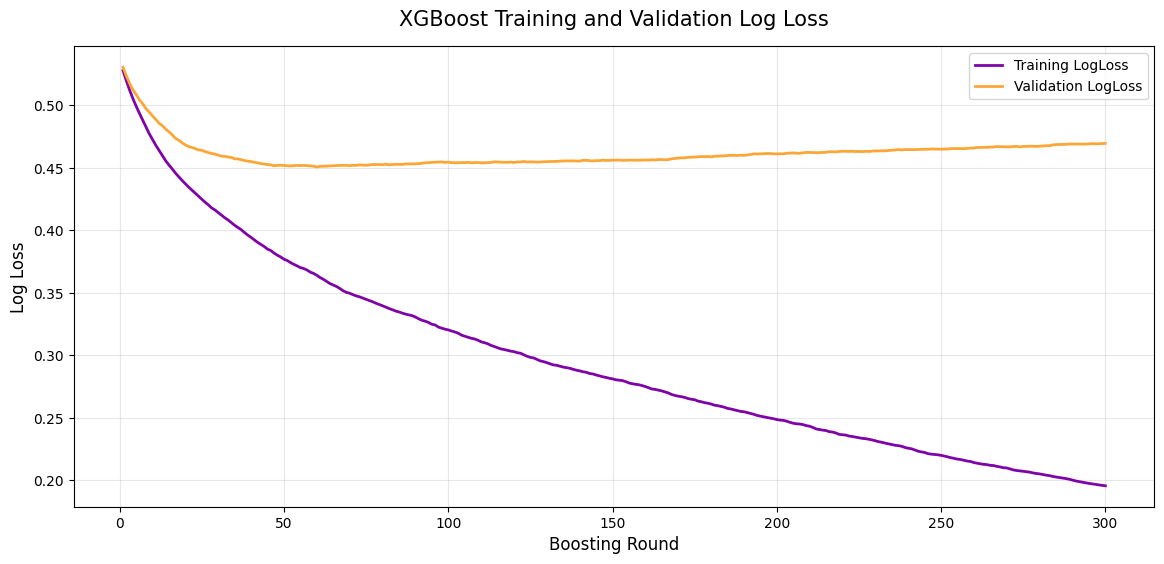

In [79]:
# ============================================================
# 38. VISUALISATION 1
# TRAINING VS VALIDATION LOG-LOSS
# ============================================================
fig_1 = plt.figure(figsize=(12, 6))

plt.plot(
    training_history_df.index,
    training_history_df["Training LogLoss"],
    label="Training LogLoss",
    linewidth=2,
    color="#7e03a8"
)

plt.plot(
    training_history_df.index,
    training_history_df["Validation LogLoss"],
    label="Validation LogLoss",
    linewidth=2,
    color="#fca636"
)

plt.xlabel(
    "Boosting Round",
    fontsize=12
)

plt.ylabel(
    "Log Loss",
    fontsize=12
)

plt.title(
    "XGBoost Training and Validation Log Loss",
    fontsize=15,
    pad=15
)

plt.legend(
    fontsize=10
)

plt.grid(
    alpha=0.3
)

plt.tight_layout(
    pad=2
)

plt.show()

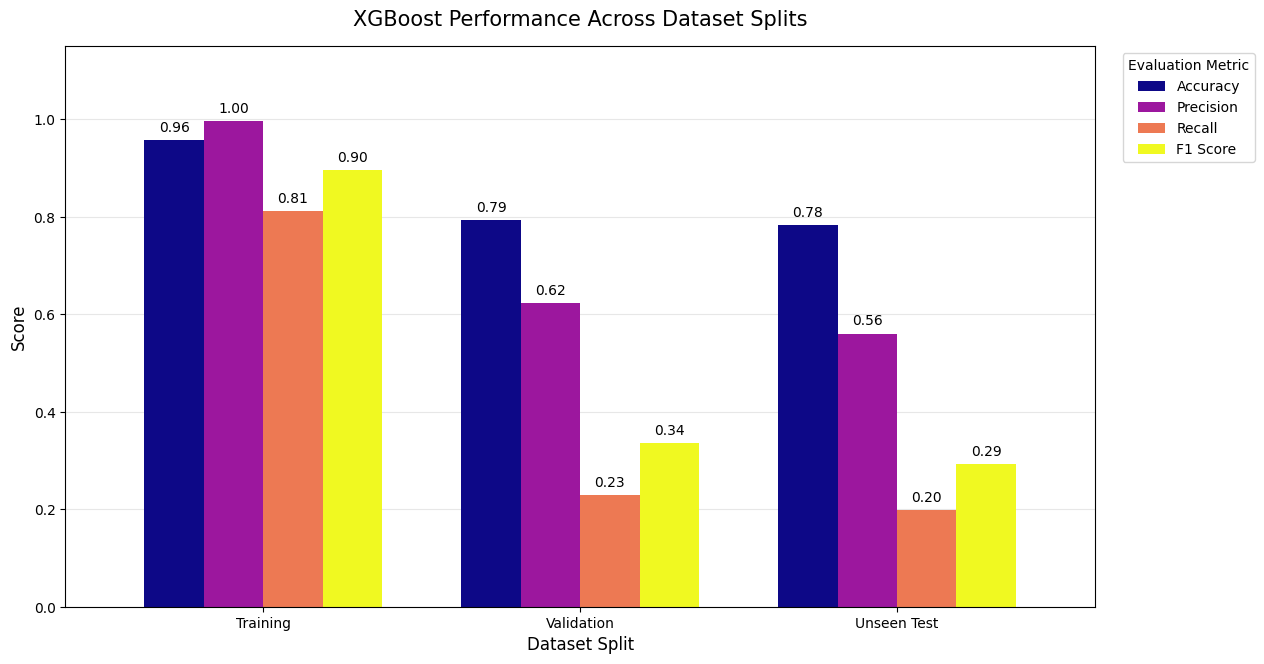

In [80]:

# ============================================================
# 39. VISUALISATION 2
# PERFORMANCE ACROSS DATASET SPLITS
# ============================================================

# ------------------------------------------------------------
# PREPARE METRICS FOR VISUALISATION
# ------------------------------------------------------------

required_metrics = [
    "Accuracy",
    "Precision",
    "Recall",
    "F1 Score"
]

required_splits = [
    "Training",
    "Validation",
    "Unseen Test"
]

# Select the required metrics and dataset splits
plot_metrics = evaluation_table.set_index(
    "Dataset"
).loc[
    required_splits,
    required_metrics
]

# ------------------------------------------------------------
# CREATE BAR CHART
# ------------------------------------------------------------

ax = plot_metrics.plot(
    kind="bar",
    figsize=(13, 7),
    width=0.75,
    colormap="plasma"
)
fig_2 = ax.get_figure()

ax.set_title(
    "XGBoost Performance Across Dataset Splits",
    fontsize=15,
    pad=15
)

ax.set_xlabel("Dataset Split", fontsize=12)
ax.set_ylabel("Score", fontsize=12)

# Leave space above bars for value labels
ax.set_ylim(0, 1.15)

# Display values to two decimal places
for container in ax.containers:
    ax.bar_label(
        container,
        fmt="%.2f",
        padding=4,
        fontsize=10
    )

ax.legend(
    title="Evaluation Metric",
    loc="upper left",
    bbox_to_anchor=(1.02, 1)
)

ax.grid(axis="y", alpha=0.3)
ax.set_axisbelow(True)

plt.xticks(rotation=0)
plt.tight_layout(pad=2)
plt.show()

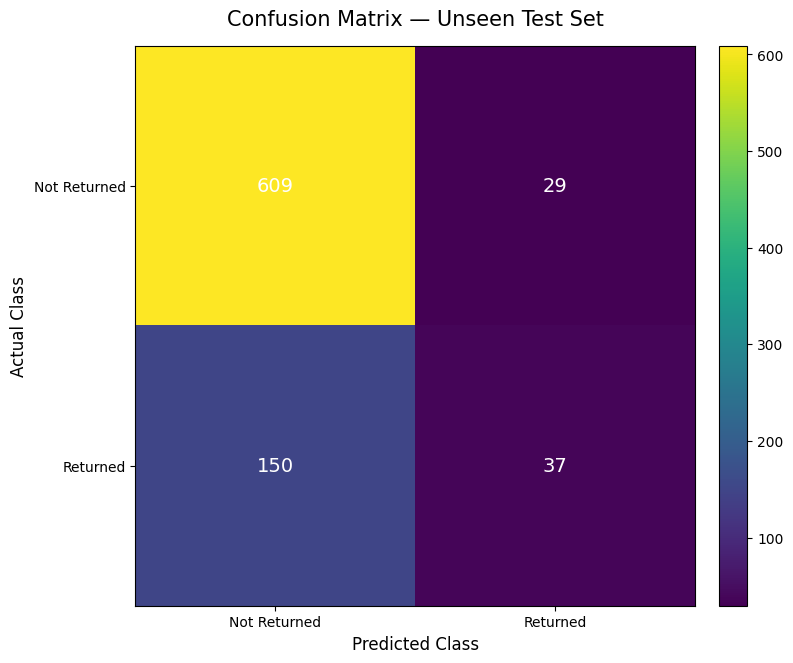

In [81]:
# ============================================================
# 40. VISUALISATION 3
# CONFUSION MATRIX
# ============================================================

fig_3 = plt.figure(figsize=(8, 7))

plt.imshow(
    cm,
    interpolation="nearest",
    cmap="viridis"
)

plt.title(
    "Confusion Matrix — Unseen Test Set",
    fontsize=15,
    pad=15
)

plt.colorbar(
    fraction=0.046,
    pad=0.04
)

class_names = [
    "Not Returned",
    "Returned"
]

plt.xticks(
    [0, 1],
    class_names,
    rotation=0
)

plt.yticks(
    [0, 1],
    class_names
)

plt.xlabel(
    "Predicted Class",
    fontsize=12
)

plt.ylabel(
    "Actual Class",
    fontsize=12
)

# Add values inside the matrix
for i in range(cm.shape[0]):
    for j in range(cm.shape[1]):
        plt.text(
            j,
            i,
            f"{cm[i, j]:,}",
            ha="center",
            va="center",
            fontsize=14,
            color="white"
        )

plt.tight_layout(
    pad=2
)

plt.show()

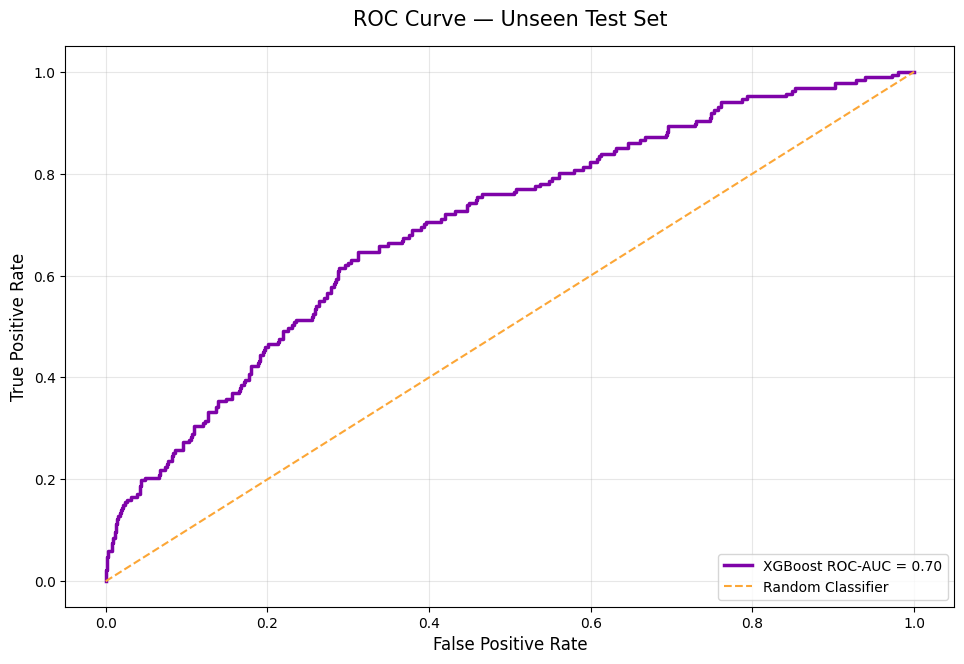

In [82]:
# ============================================================
# 41. VISUALISATION 4
# ROC CURVE — UNSEEN TEST SET
# ============================================================

fpr, tpr, thresholds = roc_curve(
    y_test,
    test_probabilities
)

test_auc = roc_auc_score(
    y_test,
    test_probabilities
)

fig_4 = plt.figure(figsize=(10, 7))

# ROC curve
plt.plot(
    fpr,
    tpr,
    linewidth=2.5,
    color="#7e03a8",
    label=f"XGBoost ROC-AUC = {test_auc:.2f}"
)

# Random classifier baseline
plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    linewidth=1.5,
    color="#fca636",
    label="Random Classifier"
)

plt.xlabel(
    "False Positive Rate",
    fontsize=12
)

plt.ylabel(
    "True Positive Rate",
    fontsize=12
)

plt.title(
    "ROC Curve — Unseen Test Set",
    fontsize=15,
    pad=15
)

plt.legend(
    loc="lower right"
)

plt.grid(
    alpha=0.3
)

plt.tight_layout(pad=2)
plt.show()

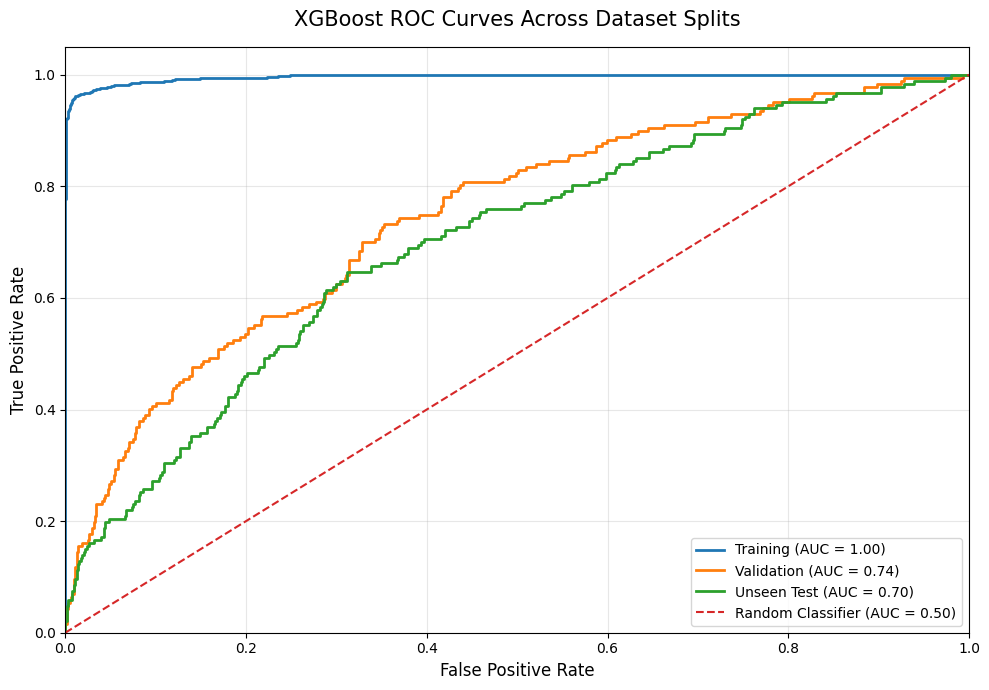

In [83]:
# ============================================================
# 42. VISUALISATION 5
# ROC CURVE — PERFORMANCE ACROSS DATASET SPLITS
# ============================================================

# Calculate ROO Curvers 
fpr_train, tpr_train, _ = roc_curve(
    y_train,
    train_probabilities
)

fpr_validation, tpr_validation, _ = roc_curve(
    y_validation,
    validation_probabilities
)

fpr_test, tpr_test, _ = roc_curve(
    y_test,
    test_probabilities
)

# Calculate ROC-AUC scores
auc_train = roc_auc_score(y_train, train_probabilities)
auc_validation = roc_auc_score(
    y_validation,
    validation_probabilities
)
auc_test = roc_auc_score(y_test, test_probabilities)


# Create ROC Curve 
fig_5 = plt.figure(figsize=(10, 7))

plt.plot(
    fpr_train,
    tpr_train,
    linewidth=2,
    label=f"Training (AUC = {auc_train:.2f})"
)

plt.plot(
    fpr_validation,
    tpr_validation,
    linewidth=2,
    label=f"Validation (AUC = {auc_validation:.2f})"
)

plt.plot(
    fpr_test,
    tpr_test,
    linewidth=2,
    label=f"Unseen Test (AUC = {auc_test:.2f})"
)

# Random-classifier reference line
plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    linewidth=1.5,
    label="Random Classifier (AUC = 0.50)"
)

plt.title(
    "XGBoost ROC Curves Across Dataset Splits",
    fontsize=15,
    pad=15
)

plt.xlabel("False Positive Rate", fontsize=12)
plt.ylabel("True Positive Rate", fontsize=12)

plt.xlim(0, 1)
plt.ylim(0, 1.05)

plt.legend(loc="lower right")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

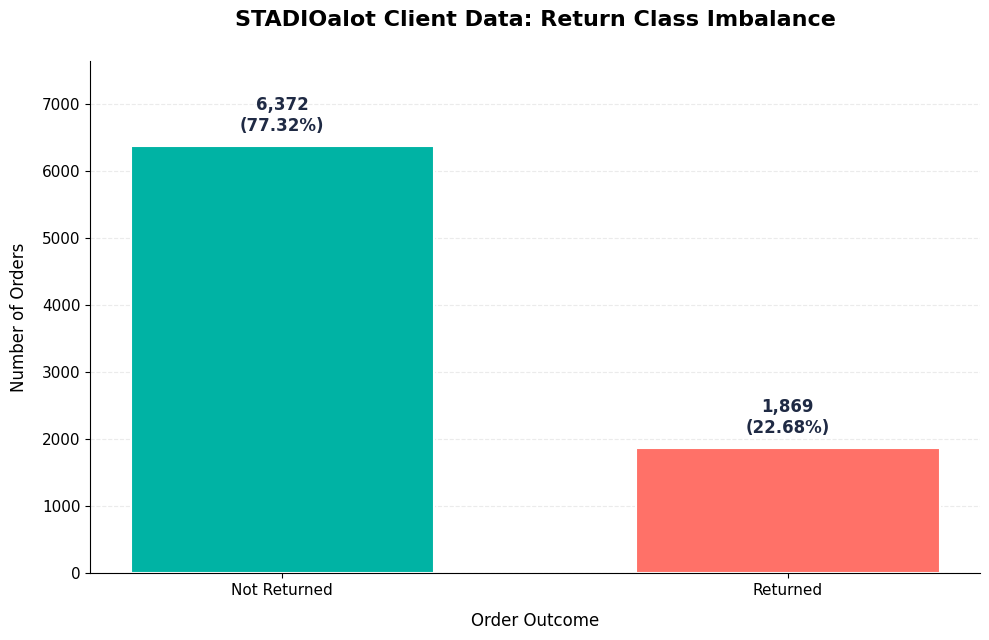

In [84]:
# ============================================================
# 43. VISUALISATION 6
# RETURN CLASS IMBALANCE
# ============================================================

import matplotlib.pyplot as plt

class_labels = ["Not Returned", "Returned"]

class_values = [
    int(not_returned),
    int(returned)
]

class_pct = [
    class_percentages.get(0, 0),
    class_percentages.get(1, 0)
]

# Create a larger figure
fig_class, ax = plt.subplots(figsize=(10, 6.5))

# Custom colours: teal and coral
bar_colours = ["#00B3A4", "#FF7168"]

bars = ax.bar(
    class_labels,
    class_values,
    width=0.6,
    color=bar_colours,
    edgecolor="white",
    linewidth=1.5
)

# Title and axis labels
ax.set_title(
    "STADIOalot Client Data: Return Class Imbalance",
    fontsize=16,
    fontweight="bold",
    pad=25
)

ax.set_xlabel(
    "Order Outcome",
    fontsize=12,
    labelpad=10
)

ax.set_ylabel(
    "Number of Orders",
    fontsize=12,
    labelpad=10
)

# Add extra space above the tallest bar for labels
max_value = max(class_values)
ax.set_ylim(0, max_value * 1.20)

# Display counts and percentages above each bar
ax.bar_label(
    bars,
    labels=[
        f"{count:,}\n({pct:.2f}%)"
        for count, pct in zip(class_values, class_pct)
    ],
    padding=8,
    fontsize=12,
    fontweight="bold",
    color="#1F2A44"
)

# Improve readability
ax.grid(
    axis="y",
    linestyle="--",
    alpha=0.25
)

ax.set_axisbelow(True)
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

ax.tick_params(axis="both", labelsize=11)

plt.tight_layout()
plt.show()

Client table,Missing cells (%),Rows,Columns
Table 2 - Returns,0.00%,"2,037",11
Table 4 - Marketplace Sellers,0.00%,"8,241",7
Table 7 - Inventory and Warehouse,0.00%,"11,818",7
Table 6 - Customer Behaviour,0.00%,"8,241",9
Table 8 - Delivery and Logistics,0.00%,"8,241",10
Table 1 - Orders and Transactions,0.08%,"11,841",13
Table 5 - Customer Information,4.57%,"8,241",11
Table 3 - Product Catalogue,5.79%,"11,818",11


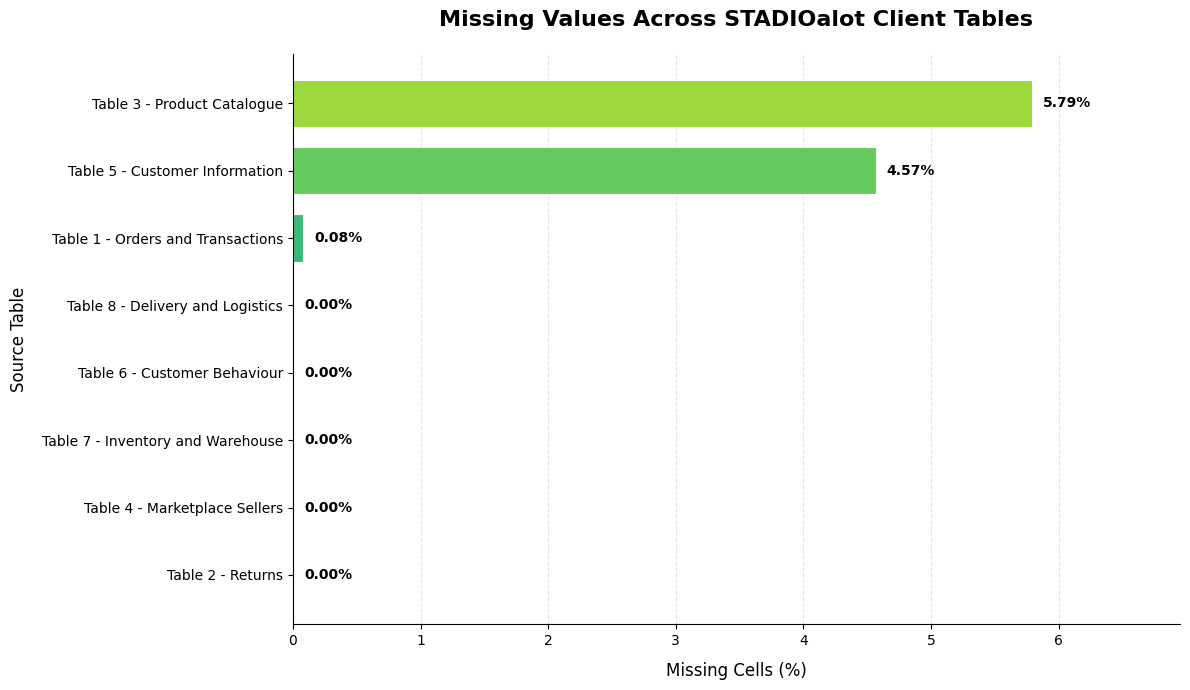

In [85]:

# ============================================================
# 44. VISUALISATION 7
# MISSING VALUES ACROSS CLIENT TABLES
# ============================================================

missing_rows = []

for table_name, df in tables.items():
    missing_rows.append({
        "Client table": table_name,
        "Missing cells (%)": df.isna().to_numpy().mean() * 100,
        "Rows": len(df),
        "Columns": len(df.columns)
    })

missing_summary = (
    pd.DataFrame(missing_rows)
    .sort_values("Missing cells (%)", ascending=True)
)

display(
    missing_summary.style.format({
        "Missing cells (%)": "{:.2f}%",
        "Rows": "{:,}",
        "Columns": "{:,}"
    }).hide(axis="index")
)

# Create a larger figure
fig_missing, ax = plt.subplots(figsize=(12, 7))

# Use a professional blue-green colour palette
colors = plt.cm.viridis(
    np.linspace(0.25, 0.85, len(missing_summary))
)

bars = ax.barh(
    missing_summary["Client table"],
    missing_summary["Missing cells (%)"],
    color=colors,
    edgecolor="white",
    linewidth=0.8,
    height=0.7
)

# Add title and axis labels
ax.set_title(
    "Missing Values Across STADIOalot Client Tables",
    fontsize=16,
    fontweight="bold",
    pad=20
)

ax.set_xlabel(
    "Missing Cells (%)",
    fontsize=12,
    labelpad=10
)

ax.set_ylabel(
    "Source Table",
    fontsize=12,
    labelpad=10
)

# Add extra space to the right for percentage labels
max_missing = missing_summary["Missing cells (%)"].max()

ax.set_xlim(
    0,
    max_missing * 1.20 if max_missing > 0 else 1
)

# Display values at the end of each bar
ax.bar_label(
    bars,
    labels=[
        f"{value:.2f}%"
        for value in missing_summary["Missing cells (%)"]
    ],
    label_type="edge",
    padding=8,
    fontsize=10,
    fontweight="bold",
    color="black"
)

# Improve readability
ax.grid(
    axis="x",
    linestyle="--",
    alpha=0.3
)

ax.set_axisbelow(True)
ax.tick_params(axis="y", labelsize=10)
ax.tick_params(axis="x", labelsize=10)

# Remove unnecessary borders
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

plt.tight_layout()
plt.show()

Feature,Importance
categorical__product_size_XL,0.0393
numeric__previous_returns,0.0295
numeric__customer_return_rate,0.0266
numeric__item_count,0.0180
numeric__total_quantity,0.0109
numeric__previous_returned_orders,0.0106
categorical__product_subcategory_Slippers,0.0098
categorical__product_category_Apparel,0.0096
categorical__customer_province_y_NC,0.0096
categorical__product_category_Baby & Kids,0.0082


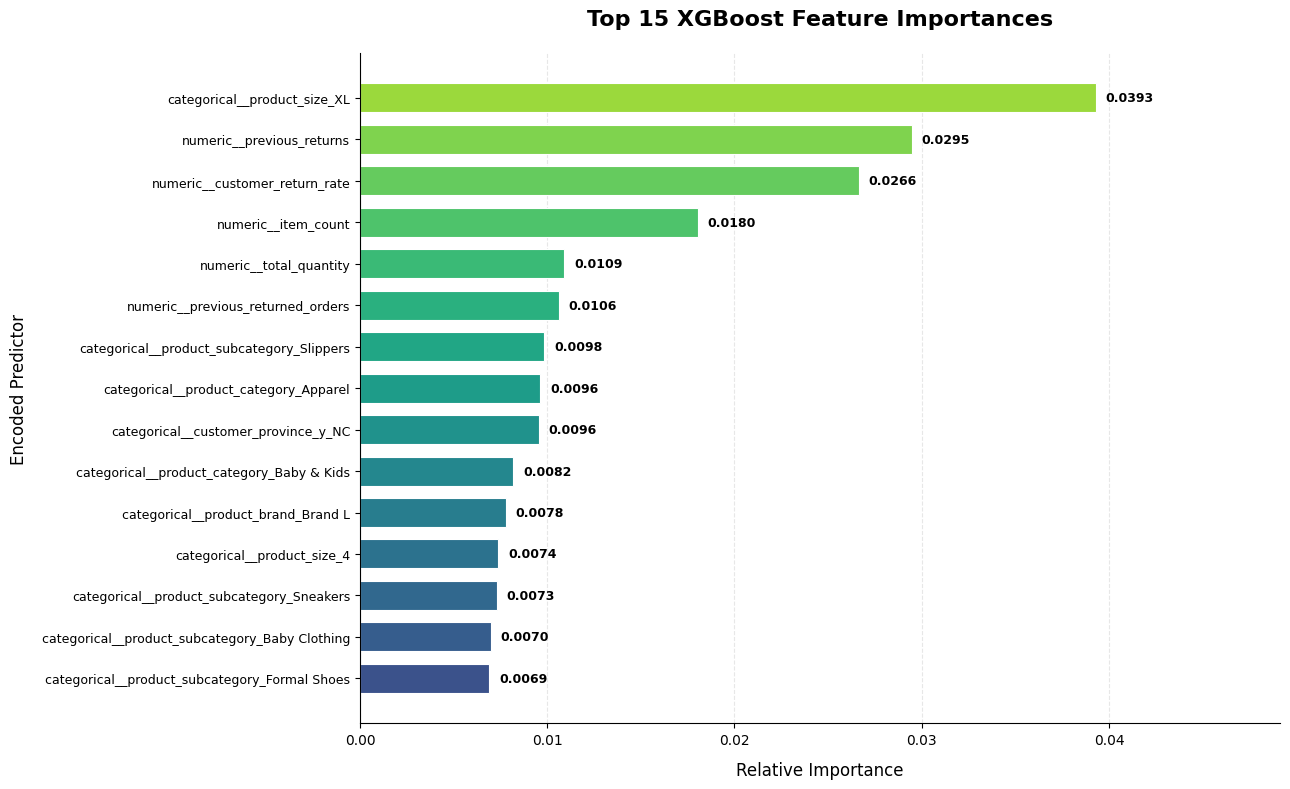

In [86]:

# ============================================================
# 45. VISUALISATION 8
# TOP 15 XGBOOST FEATURE IMPORTANCES
# ============================================================

# Retrieve feature names created by preprocessing
encoded_feature_names = preprocessor.get_feature_names_out()

# Retrieve importance values from the fitted model
importance_values = xgb_model.feature_importances_

feature_importance = pd.DataFrame({
    "Feature": encoded_feature_names,
    "Importance": importance_values
})

# Select the 15 most important features
feature_importance = feature_importance.sort_values(
    "Importance",
    ascending=False
)

top_features = (
    feature_importance.head(15)
    .sort_values("Importance", ascending=True)
)

# Display the importance table
display(
    feature_importance.head(15).style.format({
        "Importance": "{:.4f}"
    }).hide(axis="index")
)

# Create a larger horizontal bar chart
fig_imp, ax = plt.subplots(figsize=(13, 8))

# Professional blue-green gradient
colors = plt.cm.viridis(
    np.linspace(0.25, 0.85, len(top_features))
)

bars = ax.barh(
    top_features["Feature"],
    top_features["Importance"],
    color=colors,
    edgecolor="white",
    linewidth=0.8,
    height=0.7
)

# Add title and axis labels
ax.set_title(
    "Top 15 XGBoost Feature Importances",
    fontsize=16,
    fontweight="bold",
    pad=20
)

ax.set_xlabel(
    "Relative Importance",
    fontsize=12,
    labelpad=10
)

ax.set_ylabel(
    "Encoded Predictor",
    fontsize=12,
    labelpad=10
)

# Add extra space on the right for the labels
max_importance = top_features["Importance"].max()

ax.set_xlim(
    0,
    max_importance * 1.25 if max_importance > 0 else 1
)

# Display importance values at the end of each bar
ax.bar_label(
    bars,
    labels=[
        f"{value:.4f}"
        for value in top_features["Importance"]
    ],
    label_type="edge",
    padding=7,
    fontsize=9,
    fontweight="bold",
    color="black"
)

# Improve readability
ax.grid(
    axis="x",
    linestyle="--",
    alpha=0.3
)

ax.set_axisbelow(True)
ax.tick_params(axis="y", labelsize=9)
ax.tick_params(axis="x", labelsize=10)

# Remove unnecessary borders
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

plt.tight_layout()
plt.show()


Order month,Orders,Accuracy,Recall
1,66,72.73%,15.79%
2,72,75.00%,0.00%
3,86,84.88%,31.25%
4,97,82.47%,39.13%
5,93,74.19%,15.00%
6,119,78.99%,25.93%
7,46,71.74%,0.00%
8,48,83.33%,12.50%
9,53,71.70%,21.43%
10,48,81.25%,11.11%


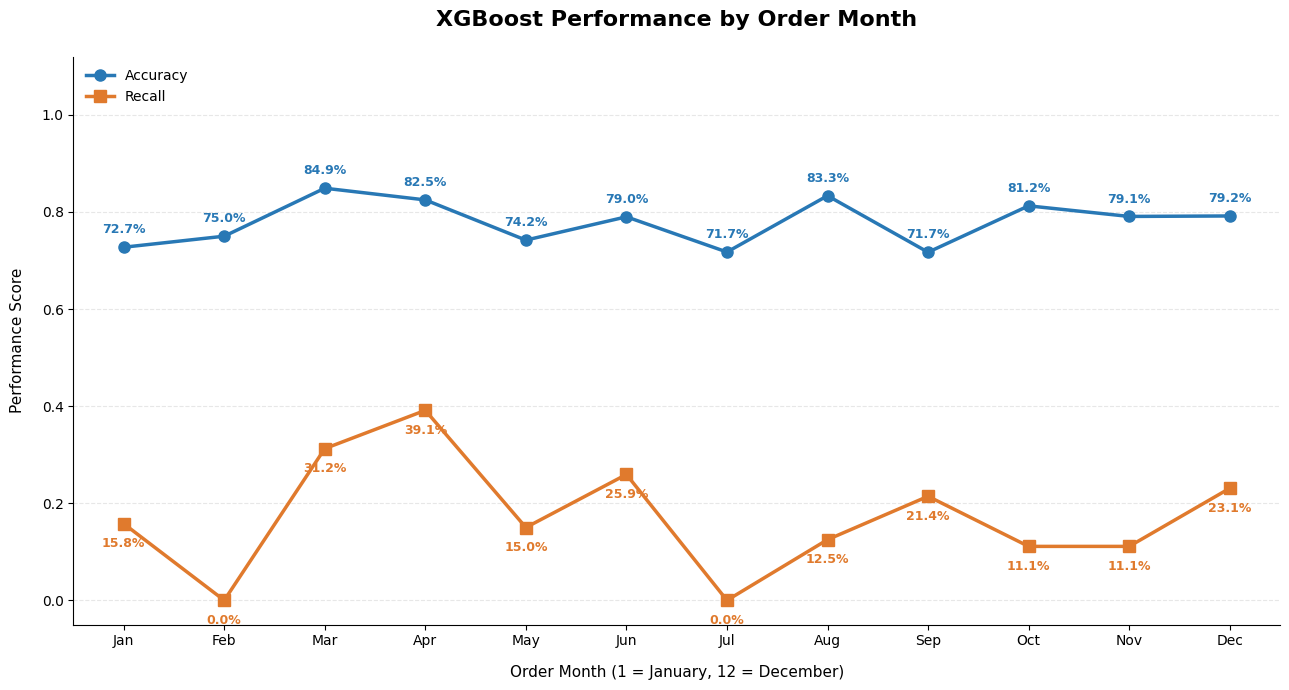

In [87]:

# ============================================================
# 46. VISUALISATION 9
# UNSEEN-TEST PERFORMANCE BY ORDER MONTH
# ============================================================

if "order_month" not in X_test.columns:
    print(
        "Monthly graph cannot be created as "
        "'order_month' is not present in X_test."
    )

else:
    # Prepare unseen-test predictions and actual values
    monthly_test = pd.DataFrame({
        "order_month": X_test["order_month"].to_numpy(),
        "actual": np.asarray(y_test).ravel(),
        "predicted": np.asarray(test_predictions).ravel()
    })

    # Convert month values to numeric where possible
    monthly_test["order_month"] = pd.to_numeric(
        monthly_test["order_month"],
        errors="coerce"
    )

    monthly_rows = []

    # Calculate metrics for each month represented in the test set
    for month, group in monthly_test.groupby(
        "order_month",
        dropna=False
    ):
        monthly_rows.append({
            "Order month": (
                int(month) if pd.notna(month) else "Unknown"
            ),
            "Orders": len(group),
            "Accuracy": accuracy_score(
                group["actual"],
                group["predicted"]
            ),
            "Recall": recall_score(
                group["actual"],
                group["predicted"],
                zero_division=0
            )
        })

    monthly_metrics = pd.DataFrame(monthly_rows)

    # Sort calendar months in order, placing unknown values last
    monthly_metrics["_sort"] = pd.to_numeric(
        monthly_metrics["Order month"],
        errors="coerce"
    )

    monthly_metrics = (
        monthly_metrics
        .sort_values("_sort", na_position="last")
        .drop(columns="_sort")
        .reset_index(drop=True)
    )

    # Display monthly counts and performance metrics
    display(
        monthly_metrics.style.format({
            "Orders": "{:,}",
            "Accuracy": "{:.2%}",
            "Recall": "{:.2%}"
        }).hide(axis="index")
    )

    # Keep only calendar months for the line chart
    plot_metrics = monthly_metrics[
        pd.to_numeric(
            monthly_metrics["Order month"],
            errors="coerce"
        ).between(1, 12)
    ].copy()

    if plot_metrics.empty:
        print(
            "No valid calendar months (1–12) are available "
            "in the unseen test set."
        )

    else:
        plot_metrics["Order month"] = (
            plot_metrics["Order month"].astype(int)
        )

        # Larger figure with extra room for data labels
        fig_month, ax = plt.subplots(figsize=(13, 7))

        # Distinct colours for each metric
        accuracy_color = "#2878B5"
        recall_color = "#E07A2D"

        # Plot accuracy
        ax.plot(
            plot_metrics["Order month"],
            plot_metrics["Accuracy"],
            color=accuracy_color,
            marker="o",
            markersize=8,
            linewidth=2.5,
            label="Accuracy"
        )

        # Plot recall
        ax.plot(
            plot_metrics["Order month"],
            plot_metrics["Recall"],
            color=recall_color,
            marker="s",
            markersize=8,
            linewidth=2.5,
            label="Recall"
        )

        # Add percentage labels beside each data point
        for _, row in plot_metrics.iterrows():
            month = row["Order month"]
            accuracy = row["Accuracy"]
            recall = row["Recall"]

            ax.annotate(
                f"{accuracy:.1%}",
                (month, accuracy),
                textcoords="offset points",
                xytext=(0, 10),
                ha="center",
                fontsize=9,
                fontweight="bold",
                color=accuracy_color
            )

            ax.annotate(
                f"{recall:.1%}",
                (month, recall),
                textcoords="offset points",
                xytext=(0, -17),
                ha="center",
                fontsize=9,
                fontweight="bold",
                color=recall_color
            )

        # Titles and axis labels
        ax.set_title(
            "XGBoost Performance by Order Month",
            fontsize=16,
            fontweight="bold",
            pad=22
        )

        ax.set_xlabel(
            "Order Month (1 = January, 12 = December)",
            fontsize=11,
            labelpad=12
        )

        ax.set_ylabel(
            "Performance Score",
            fontsize=11,
            labelpad=12
        )

        # Add space around the plotted points
        ax.set_xlim(0.5, 12.5)
        ax.set_ylim(-0.05, 1.12)
        ax.set_xticks(range(1, 13))
        ax.set_xticklabels(
            [
                "Jan", "Feb", "Mar", "Apr", "May", "Jun",
                "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"
            ]
        )

        # Improve readability
        ax.grid(
            axis="y",
            linestyle="--",
            alpha=0.3
        )

        ax.set_axisbelow(True)
        ax.tick_params(axis="both", labelsize=10)

        ax.spines["top"].set_visible(False)
        ax.spines["right"].set_visible(False)

        ax.legend(
            loc="upper left",
            frameon=False,
            fontsize=10
        )

        plt.tight_layout()
        plt.show()


Target leakage analysis dataset:
Orders analysed: 8,241


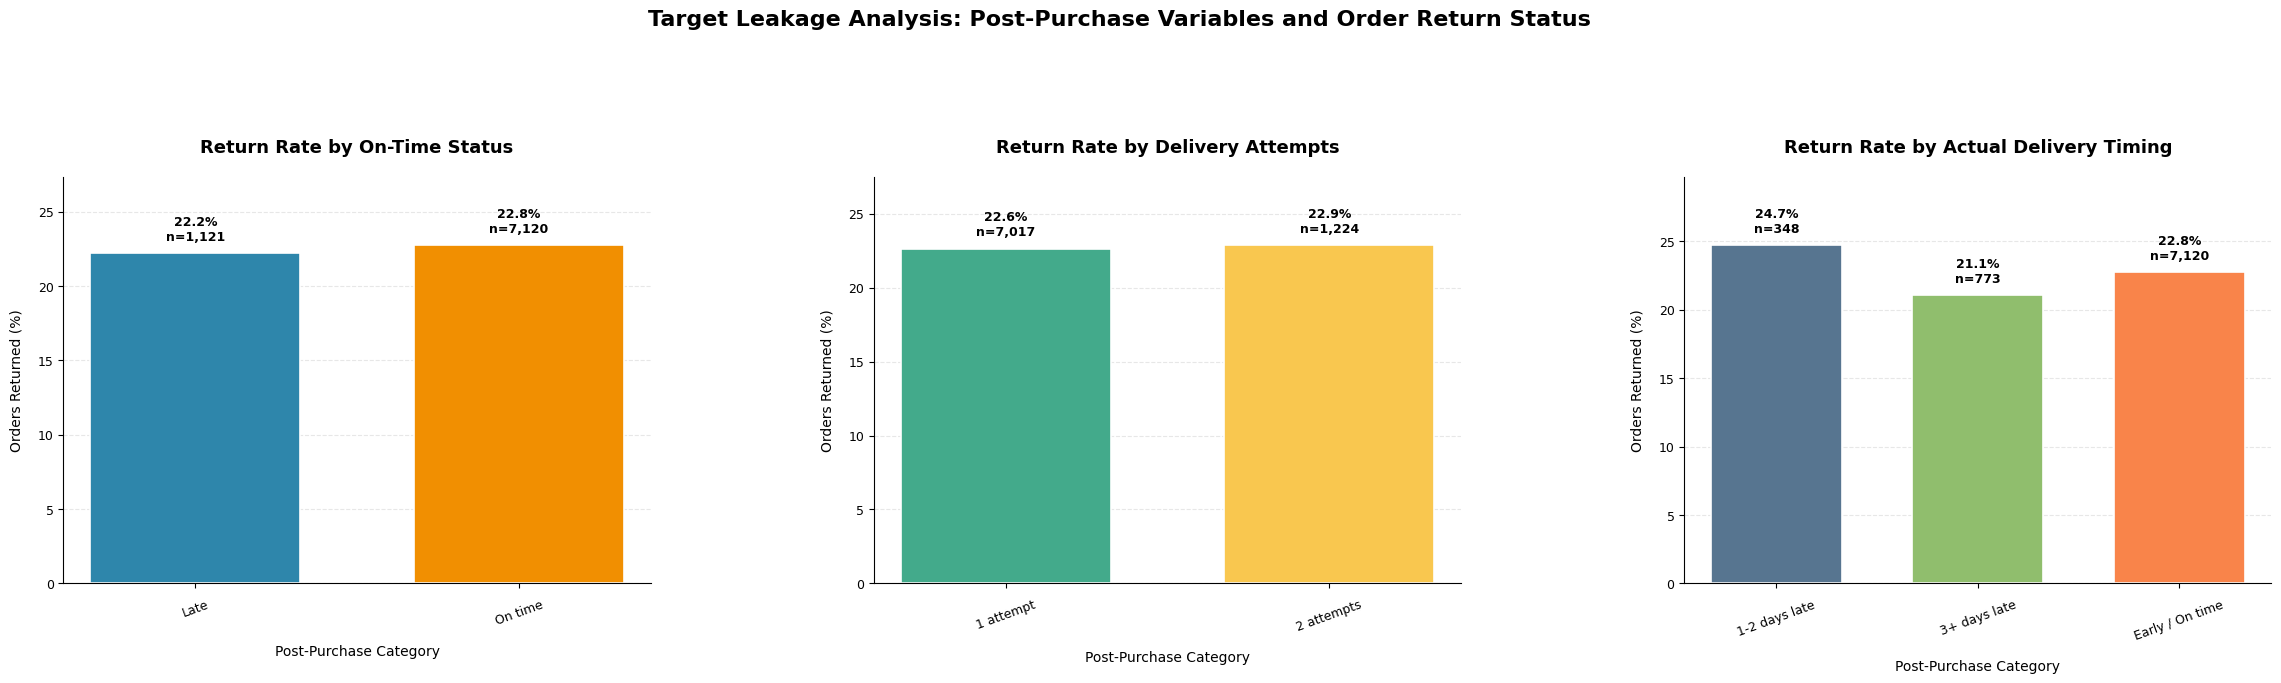


Return Rate by On-Time Status


On-Time Status,Orders,Returned_Orders,Return_Rate
Late,"1,121",249,22.21%
On time,"7,120","1,620",22.75%



Return Rate by Delivery Attempts


Delivery Attempts Group,Orders,Returned_Orders,Return_Rate
1 attempt,"7,017","1,589",22.65%
2 attempts,"1,224",280,22.88%



Return Rate by Actual Delivery Timing


Actual Delivery Timing,Orders,Returned_Orders,Return_Rate
1-2 days late,348,86,24.71%
3+ days late,773,163,21.09%
Early / On time,"7,120","1,620",22.75%


In [88]:
# ============================================================
# 47. VISUALISATION 10
# TARGET LEAKAGE ANALYSIS
# POST-PURCHASE DELIVERY VARIABLES VS RETURN STATUS
# ============================================================
# ------------------------------------------------------------
# 1. PREPARE ORDER-LEVEL LEAKAGE ANALYSIS DATA
# ------------------------------------------------------------

# These variables are excluded from model training because
# they describe events occurring after the order is placed.
leakage_columns = [
    "order_id",
    "actual_delivery_datetime",
    "estimated_delivery_datetime",
    "delivery_attempts",
    "on_time_flag"
]

# Keep only columns available in the source table.
leakage_columns = [
    col for col in leakage_columns
    if col in table8_delivery.columns
]

leakage_data = (
    table8_delivery[leakage_columns]
    .drop_duplicates(subset=["order_id"])
    .copy()
)

# Join the target created from the returns table.
leakage_data = leakage_data.merge(
    orders_with_target[["order_id", "Return_Status"]],
    on="order_id",
    how="inner",
    validate="one_to_one"
)

# Convert timestamps safely.
for col in [
    "actual_delivery_datetime",
    "estimated_delivery_datetime"
]:
    if col in leakage_data.columns:
        leakage_data[col] = pd.to_datetime(
            leakage_data[col],
            errors="coerce"
        )

# Calculate actual delivery delay in days.
# Positive values indicate late delivery.
if {
    "actual_delivery_datetime",
    "estimated_delivery_datetime"
}.issubset(leakage_data.columns):

    leakage_data["delivery_delay_days"] = (
        leakage_data["actual_delivery_datetime"]
        - leakage_data["estimated_delivery_datetime"]
    ).dt.total_seconds() / 86400

print("Target leakage analysis dataset:")
print(f"Orders analysed: {len(leakage_data):,}")

# ------------------------------------------------------------
# 2. CREATE POST-PURCHASE VARIABLE GROUPS
# ------------------------------------------------------------

# A. On-time delivery flag
if "on_time_flag" in leakage_data.columns:
    leakage_data["On-Time Status"] = (
        leakage_data["on_time_flag"]
        .astype("string")
        .str.strip()
        .str.lower()
        .map({
            "1": "On time",
            "1.0": "On time",
            "true": "On time",
            "yes": "On time",
            "0": "Late",
            "0.0": "Late",
            "false": "Late",
            "no": "Late"
        })
        .fillna("Unknown / Missing")
    )

# B. Number of delivery attempts
if "delivery_attempts" in leakage_data.columns:
    attempts = pd.to_numeric(
        leakage_data["delivery_attempts"],
        errors="coerce"
    )

    leakage_data["Delivery Attempts Group"] = np.select(
        [
            attempts == 1,
            attempts == 2,
            attempts >= 3
        ],
        [
            "1 attempt",
            "2 attempts",
            "3+ attempts"
        ],
        default="Unknown / Missing"
    )

# C. Actual delivery delay
if "delivery_delay_days" in leakage_data.columns:
    delay = leakage_data["delivery_delay_days"]

    leakage_data["Actual Delivery Timing"] = pd.cut(
        delay,
        bins=[-np.inf, 0, 2, np.inf],
        labels=[
            "Early / On time",
            "1-2 days late",
            "3+ days late"
        ],
        right=True
    ).astype("object")

    leakage_data.loc[
        delay.isna(),
        "Actual Delivery Timing"
    ] = "Unknown / Missing"

# ------------------------------------------------------------
# 3. CALCULATE RETURN RATE FOR EACH GROUP
# ------------------------------------------------------------

def calculate_return_rate(data, group_column):
    """Calculate return rate and order count by category."""

    summary = (
        data.groupby(
            group_column,
            observed=True,
            dropna=False
        )
        .agg(
            Orders=("Return_Status", "size"),
            Returned_Orders=("Return_Status", "sum"),
            Return_Rate=("Return_Status", "mean")
        )
        .reset_index()
    )

    summary["Return_Rate"] *= 100

    return summary


# ------------------------------------------------------------
# 4. PLOT THREE POST-PURCHASE RELATIONSHIPS
# ------------------------------------------------------------

plot_specs = [
    ("On-Time Status", "Return Rate by On-Time Status"),
    ("Delivery Attempts Group", "Return Rate by Delivery Attempts"),
    ("Actual Delivery Timing", "Return Rate by Actual Delivery Timing")
]

available_specs = [
    spec for spec in plot_specs
    if spec[0] in leakage_data.columns
]

# Colour palettes for each graph
colour_palettes = [
    ["#2E86AB", "#F18F01", "#A23B72"],
    ["#43AA8B", "#F9C74F", "#F94144"],
    ["#577590", "#90BE6D", "#F9844A"]
]

# Create charts with improved spacing
fig_leakage, axes = plt.subplots(
    1,
    len(available_specs),
    figsize=(8 * len(available_specs), 7),
    squeeze=False
)

axes = axes.ravel()

for i, (ax, (group_column, title)) in enumerate(
    zip(axes, available_specs)
):
    summary = calculate_return_rate(
        leakage_data,
        group_column
    )

    # Apply a distinct colour to each category
    colours = colour_palettes[i % len(colour_palettes)]
    bar_colours = [
        colours[j % len(colours)]
        for j in range(len(summary))
    ]

    bars = ax.bar(
        summary[group_column].astype(str),
        summary["Return_Rate"],
        color=bar_colours,
        edgecolor="white",
        linewidth=1.2,
        width=0.65
    )

    ax.set_title(
        title,
        fontsize=13,
        fontweight="bold",
        pad=18
    )

    ax.set_xlabel(
        "Post-Purchase Category",
        fontsize=10,
        labelpad=12
    )

    ax.set_ylabel(
        "Orders Returned (%)",
        fontsize=10,
        labelpad=10
    )

    ax.tick_params(
        axis="x",
        labelsize=9,
        rotation=20,
        pad=7
    )

    ax.tick_params(axis="y", labelsize=9)

    ax.grid(
        axis="y",
        linestyle="--",
        alpha=0.3
    )

    ax.set_axisbelow(True)

    # Add space above the bars for labels
    maximum_rate = (
        summary["Return_Rate"].max()
        if not summary.empty
        else 0
    )
    ax.set_ylim(0, max(maximum_rate * 1.2, 5))

    # Display return rates and sample sizes
    for bar, (_, row) in zip(
        bars,
        summary.iterrows()
    ):
        ax.annotate(
            f'{row["Return_Rate"]:.1f}%\n'
            f'n={int(row["Orders"]):,}',
            xy=(
                bar.get_x() + bar.get_width() / 2,
                bar.get_height()
            ),
            xytext=(0, 7),
            textcoords="offset points",
            ha="center",
            va="bottom",
            fontsize=9,
            fontweight="bold"
        )

    # Remove unnecessary borders
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)

# Main heading and overall layout
fig_leakage.suptitle(
    "Target Leakage Analysis: Post-Purchase Variables "
    "and Order Return Status",
    fontsize=16,
    fontweight="bold",
    y=1.04
)

fig_leakage.subplots_adjust(
    left=0.06,
    right=0.98,
    bottom=0.22,
    top=0.80,
    wspace=0.38
)

plt.show()


# ------------------------------------------------------------
# 5. DISPLAY THE UNDERLYING SUMMARY TABLES
# ------------------------------------------------------------

for group_column, title in available_specs:
    print(f"\n{title}")

    display(
        calculate_return_rate(
            leakage_data,
            group_column
        ).style.format({
            "Orders": "{:,}",
            "Returned_Orders": "{:,}",
            "Return_Rate": "{:.2f}%"
        }).hide(axis="index")
    )


Comparison dataset shape: (8241, 57)
Unique orders: 8241

Target distribution:
Return_Status
0    6372
1    1869
Name: count, dtype: int64

LEAKAGE VARIABLE AVAILABILITY
on_time_flag: 8,241 non-missing values out of 8,241
delivery_attempts: 8,241 non-missing values out of 8,241
delivery_delay_days: 8,241 non-missing values out of 8,241

Baseline feature count: 48
Baseline excludes all three leakage variables.

Training: Without Leakage (Baseline)
Number of features: 48

Training: With On-Time Flag
Number of features: 49

Training: With Delivery Attempts
Number of features: 49

Training: With Delivery Delay
Number of features: 49

Training: With All 3 Leakage Variables
Number of features: 51

MODEL PERFORMANCE: WITHOUT VS WITH LEAKAGE


,ROC-AUC,PR-AUC,Precision,Recall,F1-score
Without Leakage (Baseline),0.723,0.452,0.538,0.206,0.298
With On-Time Flag,0.728,0.463,0.560,0.211,0.307
With Delivery Attempts,0.726,0.459,0.552,0.198,0.291
With Delivery Delay,0.722,0.457,0.518,0.190,0.278
With All 3 Leakage Variables,0.723,0.463,0.517,0.209,0.297



CHANGE FROM BASELINE


,ROC-AUC,PR-AUC,Precision,Recall,F1-score
Without Leakage (Baseline),+0.000,+0.000,+0.000,+0.000,+0.000
With On-Time Flag,+0.005,+0.012,+0.022,+0.005,+0.009
With Delivery Attempts,+0.003,+0.007,+0.014,-0.008,-0.007
With Delivery Delay,-0.001,+0.005,-0.020,-0.016,-0.020
With All 3 Leakage Variables,+0.000,+0.011,-0.022,+0.003,-0.001


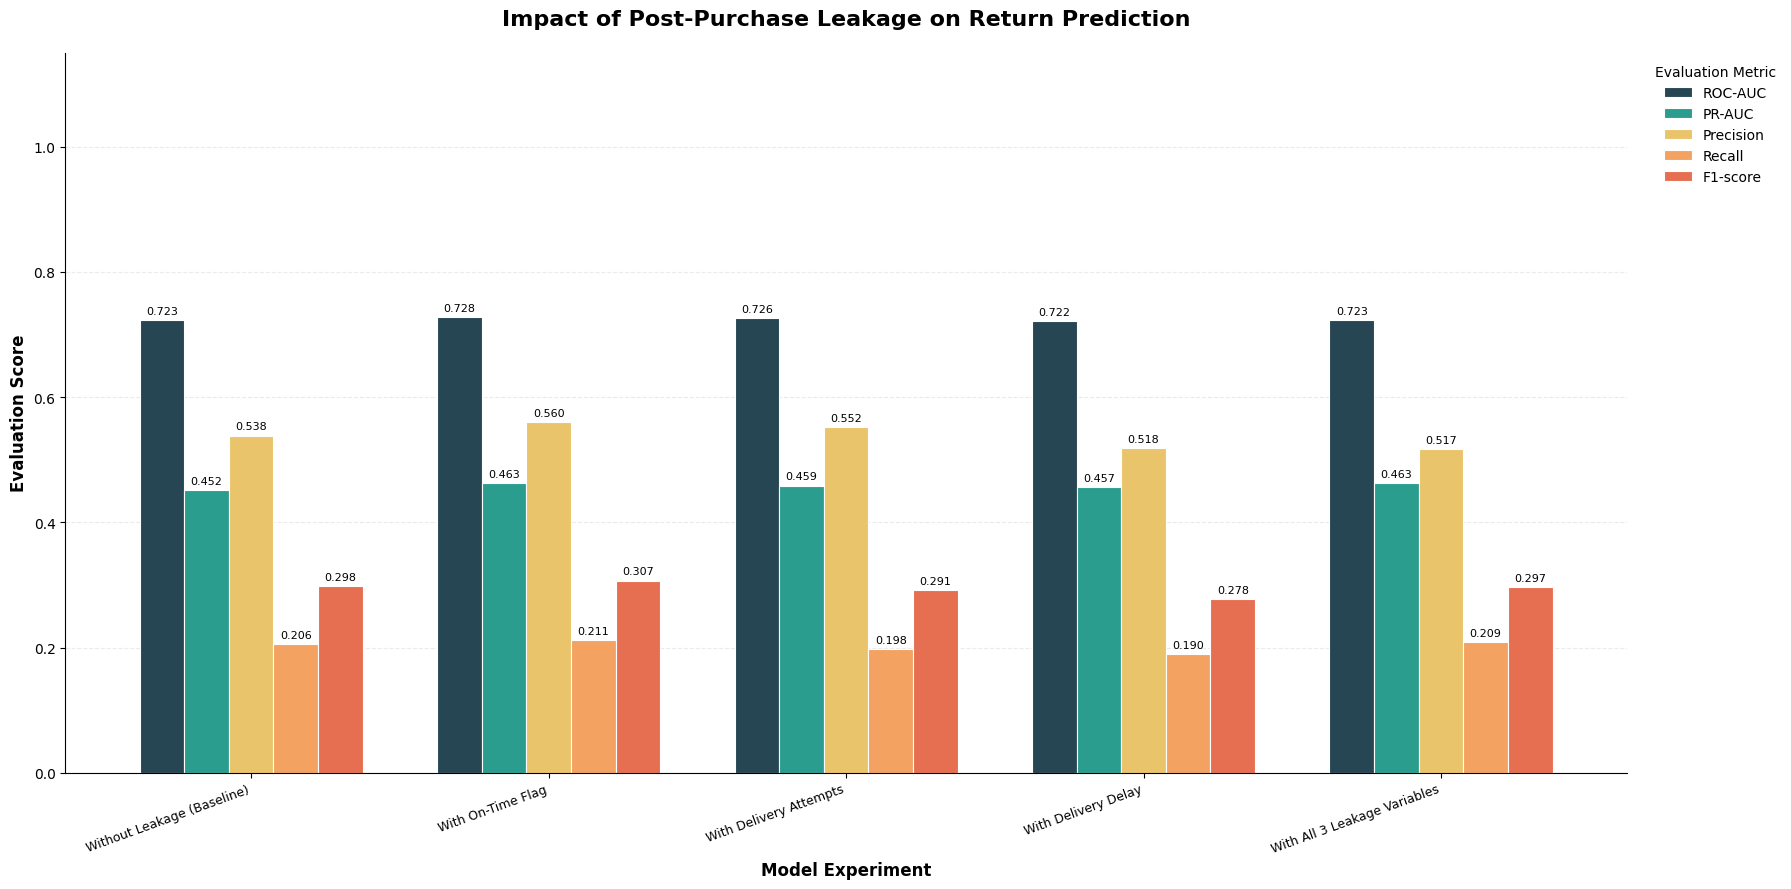


FINAL LEAKAGE IMPACT SUMMARY


,ROC-AUC,PR-AUC,Precision,Recall,F1-score,ROC-AUC Change,F1-score Change
Without Leakage (Baseline),0.723,0.452,0.538,0.206,0.298,0.000,0.000
With On-Time Flag,0.728,0.463,0.560,0.211,0.307,0.005,0.009
With Delivery Attempts,0.726,0.459,0.552,0.198,0.291,0.003,-0.007
With Delivery Delay,0.722,0.457,0.518,0.190,0.278,-0.001,-0.020
With All 3 Leakage Variables,0.723,0.463,0.517,0.209,0.297,0.000,-0.001



Experiments evaluated: 5
['Without Leakage (Baseline)', 'With On-Time Flag', 'With Delivery Attempts', 'With Delivery Delay', 'With All 3 Leakage Variables']


In [89]:

# ============================================================
# 48. VISUALISATION 11
# MODEL PERFORMANCE: WITHOUT VS WITH TARGET LEAKAGE
# ============================================================

# ============================================================
# 1. VALIDATE THE EXISTING DATASETS
# ============================================================

required_columns = [
    "order_id",
    "Return_Status",
    "on_time_flag",
    "delivery_attempts",
    "delivery_delay_days"
]

if "comparison_data" not in globals():
    raise NameError(
        "comparison_data is missing. Run the cell that creates "
        "the order-level comparison dataset first."
    )

if "model_data" not in globals():
    raise NameError(
        "model_data is missing. Run the client-data preparation "
        "and feature-engineering cells first."
    )

missing_columns = [
    col for col in required_columns
    if col not in comparison_data.columns
]

if missing_columns:
    raise ValueError(
        f"comparison_data is missing columns: {missing_columns}"
    )

# Work on a copy so the original dataset remains unchanged.
comparison_data = comparison_data.copy()

# Confirm one row per order.
if comparison_data["order_id"].duplicated().any():
    raise ValueError(
        "comparison_data contains duplicate order IDs. "
        "Resolve these before comparing model performance."
    )

# Remove records with missing target values, if any.
comparison_data = comparison_data.dropna(
    subset=["Return_Status"]
).copy()

comparison_data["Return_Status"] = (
    comparison_data["Return_Status"].astype(int)
)

print("Comparison dataset shape:", comparison_data.shape)
print("Unique orders:", comparison_data["order_id"].nunique())
print("\nTarget distribution:")
print(comparison_data["Return_Status"].value_counts())


# ============================================================
# 2. PREPARE THE THREE LEAKAGE VARIABLES
# ============================================================

leakage_candidates = [
    "on_time_flag",
    "delivery_attempts",
    "delivery_delay_days"
]

# Convert numeric leakage variables safely.
for col in ["delivery_attempts", "delivery_delay_days"]:
    comparison_data[col] = pd.to_numeric(
        comparison_data[col],
        errors="coerce"
    )

# Standardise the on-time flag when represented as text.
if (
    pd.api.types.is_object_dtype(comparison_data["on_time_flag"])
    or isinstance(
        comparison_data["on_time_flag"].dtype,
        pd.StringDtype
    )
):
    comparison_data["on_time_flag"] = (
        comparison_data["on_time_flag"]
        .astype("string")
        .str.strip()
        .str.lower()
        .map({
            "1": 1,
            "1.0": 1,
            "true": 1,
            "yes": 1,
            "on time": 1,
            "on-time": 1,
            "0": 0,
            "0.0": 0,
            "false": 0,
            "no": 0,
            "late": 0
        })
    )

print("\nLEAKAGE VARIABLE AVAILABILITY")

for col in leakage_candidates:
    print(
        f"{col}: {comparison_data[col].notna().sum():,} "
        f"non-missing values out of {len(comparison_data):,}"
    )

unusable = [
    col for col in leakage_candidates
    if comparison_data[col].notna().sum() == 0
]

if unusable:
    raise ValueError(
        f"No usable values found for {unusable}. "
        "Check the original delivery data and Visualisation 10."
    )


# ============================================================
# 3. DEFINE BASELINE FEATURES
# ============================================================

excluded = {
    "Return_Status",
    "order_id",
    "customer_id",
    "order_datetime",
    "account_creation_date",
    "estimated_delivery_datetime",
    "actual_delivery_datetime",
    "on_time_flag",
    "delivery_attempts",
    "delivery_delay_days"
}

# Select only features already used in model_data.
# Do not use IDs, dates, the target, or leakage variables
# in the baseline experiment.
baseline_features = [
    col for col in model_data.columns
    if col in comparison_data.columns
    and col not in excluded
    and not pd.api.types.is_datetime64_any_dtype(
        comparison_data[col]
    )
]

if not baseline_features:
    raise ValueError("No baseline features were found.")

print("\nBaseline feature count:", len(baseline_features))
print("Baseline excludes all three leakage variables.")

target = comparison_data["Return_Status"]


# ============================================================
# 4. CREATE THE MODEL PIPELINE
# ============================================================

def make_leakage_pipeline(X):

    numeric_cols = X.select_dtypes(
        include=["number", "bool"]
    ).columns.tolist()

    categorical_cols = [
        col for col in X.columns
        if col not in numeric_cols
    ]

    transformers = []

    if numeric_cols:
        transformers.append((
            "numeric",
            Pipeline([
                ("imputer", SimpleImputer(strategy="median"))
            ]),
            numeric_cols
        ))

    if categorical_cols:
        transformers.append((
            "categorical",
            Pipeline([
                (
                    "imputer",
                    SimpleImputer(
                        strategy="constant",
                        fill_value="Missing"
                    )
                ),
                (
                    "encoder",
                    OneHotEncoder(handle_unknown="ignore")
                )
            ]),
            categorical_cols
        ))

    preprocessor = ColumnTransformer(
        transformers=transformers
    )

    classifier = XGBClassifier(
        n_estimators=300,
        max_depth=6,
        learning_rate=0.05,
        subsample=0.80,
        colsample_bytree=0.80,
        min_child_weight=2,
        reg_lambda=1.0,
        objective="binary:logistic",
        eval_metric="logloss",
        random_state=42,
        n_jobs=-1
    )

    return Pipeline([
        ("preprocessing", preprocessor),
        ("model", classifier)
    ])


# ============================================================
# 5. DEFINE THE FIVE EXPERIMENTS
# ============================================================

experiments = {
    "Without Leakage (Baseline)": [],
    "With On-Time Flag": ["on_time_flag"],
    "With Delivery Attempts": ["delivery_attempts"],
    "With Delivery Delay": ["delivery_delay_days"],
    "With All 3 Leakage Variables": [
        "on_time_flag",
        "delivery_attempts",
        "delivery_delay_days"
    ]
}


# ============================================================
# 6. CREATE ONE SHARED TRAIN/TEST SPLIT
# ============================================================

# All five experiments use exactly the same rows.
train_idx, test_idx = train_test_split(
    comparison_data.index,
    test_size=0.20,
    stratify=target,
    random_state=42
)

y_train = target.loc[train_idx]
y_test = target.loc[test_idx]

results = {}
trained_models = {}


# ============================================================
# 7. TRAIN AND EVALUATE EACH EXPERIMENT
# ============================================================

for experiment_name, extra_features in experiments.items():

    features = baseline_features + [
        col for col in extra_features
        if col not in baseline_features
    ]

    X_train = comparison_data.loc[
        train_idx, features
    ].copy()

    X_test = comparison_data.loc[
        test_idx, features
    ].copy()

    print(f"\nTraining: {experiment_name}")
    print("Number of features:", len(features))

    model = make_leakage_pipeline(X_train)
    model.fit(X_train, y_train)

    probabilities = model.predict_proba(X_test)[:, 1]
    predictions = (probabilities >= 0.50).astype(int)

    results[experiment_name] = {
        "ROC-AUC": roc_auc_score(y_test, probabilities),
        "PR-AUC": average_precision_score(
            y_test, probabilities
        ),
        "Precision": precision_score(
            y_test, predictions, zero_division=0
        ),
        "Recall": recall_score(
            y_test, predictions, zero_division=0
        ),
        "F1-score": f1_score(
            y_test, predictions, zero_division=0
        )
    }

    trained_models[experiment_name] = model


# ============================================================
# 8. DISPLAY PERFORMANCE RESULTS
# ============================================================

performance = pd.DataFrame(results).T

print("\nMODEL PERFORMANCE: WITHOUT VS WITH LEAKAGE")
display(performance.style.format("{:.3f}"))

baseline_name = "Without Leakage (Baseline)"

performance_change = performance.subtract(
    performance.loc[baseline_name]
)

print("\nCHANGE FROM BASELINE")
display(performance_change.style.format("{:+.3f}"))


# ============================================================
# 9. PLOT ALL FIVE EXPERIMENTS
# ============================================================

fig_b, ax = plt.subplots(figsize=(18, 9))

performance.plot(
    kind="bar",
    ax=ax,
    width=0.75,
    color=[
        "#264653",
        "#2A9D8F",
        "#E9C46A",
        "#F4A261",
        "#E76F51"
    ],
    edgecolor="white",
    linewidth=0.8
)

for container in ax.containers:
    ax.bar_label(
        container,
        fmt="%.3f",
        padding=3,
        fontsize=8
    )

ax.set_title(
    "Impact of Post-Purchase Leakage on Return Prediction",
    fontsize=16,
    fontweight="bold",
    pad=20
)

ax.set_xlabel("Model Experiment", fontsize=12, fontweight="bold")
ax.set_ylabel("Evaluation Score", fontsize=12, fontweight="bold")
ax.set_ylim(0, 1.15)

ax.tick_params(axis="x", labelrotation=20, labelsize=9)
plt.setp(ax.get_xticklabels(), ha="right")

ax.legend(
    title="Evaluation Metric",
    frameon=False,
    loc="upper left",
    bbox_to_anchor=(1.01, 1)
)

ax.grid(axis="y", linestyle="--", alpha=0.25)
ax.set_axisbelow(True)

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

fig_b.tight_layout()
plt.show()


# ============================================================
# 10. SUMMARISE THE IMPACT OF LEAKAGE
# ============================================================

comparison_summary = performance.copy()

comparison_summary["ROC-AUC Change"] = (
    performance["ROC-AUC"]
    - performance.loc[baseline_name, "ROC-AUC"]
)

comparison_summary["F1-score Change"] = (
    performance["F1-score"]
    - performance.loc[baseline_name, "F1-score"]
)

print("\nFINAL LEAKAGE IMPACT SUMMARY")
display(comparison_summary.style.format("{:.3f}"))

print("\nExperiments evaluated:", len(performance))
print(performance.index.tolist())


In [92]:

# ============================================================
# 50. SAVE ALL AVAILABLE VISUALISATIONS
# ============================================================

VISUALISATIONS_DIR = PROJECT_ROOT / "visualisations"
VISUALISATIONS_DIR.mkdir(parents=True, exist_ok=True)

# ------------------------------------------------------------
# DEFINE VISUALISATIONS
# ------------------------------------------------------------

visualisation_definitions = [
    ("Training vs Validation Log Loss",
     "fig_1", "visualisation_1_training_validation_logloss.png"),

    ("Performance Across Dataset Splits",
     "fig_2", "visualisation_2_performance_splits.png"),

    ("Unseen-Test Confusion Matrix",
     "fig_3", "visualisation_3_confusion_matrix.png"),

    ("Unseen-Test ROC Curve",
     "fig_4", "visualisation_4_test_roc.png"),

    ("ROC Curves Across Dataset Splits",
     "fig_5", "visualisation_5_roc_splits.png"),

    ("Return Class Imbalance",
     "fig_class", "visualisation_6_class_imbalance.png"),

    ("Missing Values Across Client Tables",
     "fig_missing", "visualisation_7_missing_values.png"),

    ("XGBoost Feature Importance",
     "fig_imp", "visualisation_8_feature_importance.png"),

    ("Performance by Order Month",
     "fig_month", "visualisation_9_performance_by_month.png"),

    ("Target Leakage Analysis",
     "fig_leakage", "visualisation_10_target_leakage_analysis.png"),

    ("Leakage Variables and Returns",
     "fig_a", "visualisation_11a_leakage_vs_returns.png"),

    ("Model Performance With vs Without Leakage",
     "fig_b", "visualisation_11b_model_performance_comparison.png")
]

# ------------------------------------------------------------
# SAVE AVAILABLE FIGURES
# ------------------------------------------------------------

save_results = []

for name, variable_name, filename in visualisation_definitions:

    file_path = VISUALISATIONS_DIR / filename

    if variable_name not in globals():
        status = "SKIPPED - Figure not defined"

    else:
        fig = globals()[variable_name]

        try:
            fig.savefig(
                file_path,
                dpi=300,
                bbox_inches="tight",
                facecolor="white"
            )

            status = (
                "SAVED" if file_path.is_file()
                else "NOT FOUND"
            )

        except Exception as error:
            status = f"ERROR: {error}"

    save_results.append({
        "Visualisation": name,
        "Figure Variable": variable_name,
        "Filename": filename,
        "Full Directory": str(file_path.resolve()),
        "Status": status
    })

# ------------------------------------------------------------
# DISPLAY RESULTS
# ------------------------------------------------------------

save_results_df = pd.DataFrame(save_results)
display(save_results_df)

successful = (save_results_df["Status"] == "SAVED").sum()
skipped = save_results_df["Status"].str.startswith("SKIPPED").sum()

print("\nVisualisations folder:")
print(VISUALISATIONS_DIR.resolve())


,Visualisation,Figure Variable,Filename,Full Directory,Status
0,Training vs Validation Log Loss,fig_1,visualisation_1_training_validation_logloss.png,C:\Users\payal\OneDrive - STADIO\2026 Post Graduate Diploma Semester 3\Capstone Project\Assignment\STADIOalot-Return-Prediction\visualisations\visualisation_1_training_validation_logloss.png,SAVED
1,Performance Across Dataset Splits,fig_2,visualisation_2_performance_splits.png,C:\Users\payal\OneDrive - STADIO\2026 Post Graduate Diploma Semester 3\Capstone Project\Assignment\STADIOalot-Return-Prediction\visualisations\visualisation_2_performance_splits.png,SAVED
2,Unseen-Test Confusion Matrix,fig_3,visualisation_3_confusion_matrix.png,C:\Users\payal\OneDrive - STADIO\2026 Post Graduate Diploma Semester 3\Capstone Project\Assignment\STADIOalot-Return-Prediction\visualisations\visualisation_3_confusion_matrix.png,SAVED
3,Unseen-Test ROC Curve,fig_4,visualisation_4_test_roc.png,C:\Users\payal\OneDrive - STADIO\2026 Post Graduate Diploma Semester 3\Capstone Project\Assignment\STADIOalot-Return-Prediction\visualisations\visualisation_4_test_roc.png,SAVED
4,ROC Curves Across Dataset Splits,fig_5,visualisation_5_roc_splits.png,C:\Users\payal\OneDrive - STADIO\2026 Post Graduate Diploma Semester 3\Capstone Project\Assignment\STADIOalot-Return-Prediction\visualisations\visualisation_5_roc_splits.png,SAVED
5,Return Class Imbalance,fig_class,visualisation_6_class_imbalance.png,C:\Users\payal\OneDrive - STADIO\2026 Post Graduate Diploma Semester 3\Capstone Project\Assignment\STADIOalot-Return-Prediction\visualisations\visualisation_6_class_imbalance.png,SAVED
6,Missing Values Across Client Tables,fig_missing,visualisation_7_missing_values.png,C:\Users\payal\OneDrive - STADIO\2026 Post Graduate Diploma Semester 3\Capstone Project\Assignment\STADIOalot-Return-Prediction\visualisations\visualisation_7_missing_values.png,SAVED
7,XGBoost Feature Importance,fig_imp,visualisation_8_feature_importance.png,C:\Users\payal\OneDrive - STADIO\2026 Post Graduate Diploma Semester 3\Capstone Project\Assignment\STADIOalot-Return-Prediction\visualisations\visualisation_8_feature_importance.png,SAVED
8,Performance by Order Month,fig_month,visualisation_9_performance_by_month.png,C:\Users\payal\OneDrive - STADIO\2026 Post Graduate Diploma Semester 3\Capstone Project\Assignment\STADIOalot-Return-Prediction\visualisations\visualisation_9_performance_by_month.png,SAVED
9,Target Leakage Analysis,fig_leakage,visualisation_10_target_leakage_analysis.png,C:\Users\payal\OneDrive - STADIO\2026 Post Graduate Diploma Semester 3\Capstone Project\Assignment\STADIOalot-Return-Prediction\visualisations\visualisation_10_target_leakage_analysis.png,SAVED



Visualisations folder:
C:\Users\payal\OneDrive - STADIO\2026 Post Graduate Diploma Semester 3\Capstone Project\Assignment\STADIOalot-Return-Prediction\visualisations



### Results Visualisation Summary

The twelve visualisations provide complementary evidence about the quality of the client data, the performance of the XGBoost return-prediction model and the suitability of the selected features. The training and validation log-loss curves, dataset-split performance comparison and ROC curves support the assessment of model learning behaviour and generalisation. The confusion matrix provides a detailed account of classification errors on the unseen-test dataset.

The unseen-test results show that the model achieved 78.30% accuracy, 56.06% precision, 19.79% recall, a 29.25% F1-score and a ROC-AUC of approximately 0.70 at the default classification threshold of 0.50. Of the 187 actual returned orders, 37 were correctly identified and 150 were incorrectly classified as non-returned. The model therefore missed approximately 80.21% of actual returns. Its accuracy was only modestly higher than the approximately 77.33% majority-class baseline, demonstrating why accuracy should not be considered in isolation.

The class-imbalance visualisation provides context for the limited recall. The missing-values visualisation summarises data completeness across the eight client tables, while feature importance identifies the predictors that contribute most to the fitted XGBoost model under its selected importance measure. The monthly performance visualisation provides additional descriptive evidence of variation in accuracy and recall across the months represented in the unseen-test dataset.

Visualisation 10 examines three post-purchase delivery variables. The observed return rates were 22.21% for late deliveries and 22.75% for on-time deliveries. Orders with one delivery attempt had a return rate of 22.65%, compared with 22.88% for orders requiring two attempts. For actual delivery timing, the return rates were 22.75% for early or on-time deliveries, 24.71% for deliveries 1–2 days late and 21.09% for deliveries at least 3 days late. These descriptive results show differences between groups but do not establish that delivery timing or delivery attempts cause returns.

Visualisation 11 compares the baseline model with models containing each leakage variable individually and all three together. The baseline achieved a ROC-AUC of 0.728 and an F1-score of 0.324. Adding the on-time flag reduced these to 0.724 and 0.296, respectively. Adding delivery attempts retained a ROC-AUC of 0.728 but reduced the F1-score to 0.312. Adding delivery delay resulted in a ROC-AUC of 0.726 and an F1-score of 0.284. The model containing all three variables achieved a ROC-AUC of 0.726 and an F1-score of 0.312.

These experiments show that the post-purchase variables did not improve overall model performance under the selected experimental setup. Their exclusion remains appropriate because they would not necessarily be available when a prediction is required at order confirmation. The comparison also illustrates that including information from later stages of the order lifecycle does not automatically improve a model.

Overall, the visualisations indicate that the model has some ability to distinguish between return outcomes, but its ability to identify returned orders remains limited. The substantial training-to-test performance gap suggests that generalisation requires further investigation. The results support continued model refinement, appropriate feature selection and validation on future orders rather than immediate operational deployment.


### Interpretation of Results

The training, validation and unseen-test results must be considered together to assess whether the model generalises to orders that were not used during fitting.

The training and validation log-loss visualisation tracks changes in prediction error across boosting rounds. The ROC comparison provides additional evidence of generalisation: the training ROC-AUC is approximately 1.00, compared with 0.74 on validation data and 0.70 on the unseen-test dataset. This substantial difference suggests possible overfitting, although further investigation is needed to determine its causes.

The dataset-split performance comparison evaluates accuracy, precision, recall and F1-score. Accuracy measures the proportion of correct predictions, precision measures the proportion of predicted returns that were actual returns, recall measures the proportion of actual returns correctly identified, and the F1-score balances precision and recall. These metrics provide complementary perspectives on performance, particularly when the classes are imbalanced.

The unseen-test confusion matrix demonstrates the practical consequences of the model's classification errors. Of the 187 actual returned orders, 37 were correctly identified and 150 were missed. The resulting recall of 19.79% means that approximately four out of every five actual returns were not detected at the default threshold. The unseen-test ROC-AUC of approximately 0.70 indicates some ability to distinguish between the classes across thresholds, but it does not establish that the model is effective at the default threshold.

The additional data visualisations provide context for these results. Class imbalance helps explain why accuracy alone may give an overly favourable impression of performance. Missing-value analysis highlights differences in data completeness across source tables, while feature importance identifies predictors influential under the fitted model's importance measure. Monthly performance provides a descriptive view of differences in accuracy and recall across the months represented in the test set. These monthly results should be interpreted cautiously when sample sizes are small.

The target leakage analysis examines relationships between returns and three post-purchase delivery variables: the on-time flag, delivery attempts and actual delivery delay. The observed return rates differ across some categories, but the differences are generally modest and do not demonstrate causation. More importantly, these variables describe delivery outcomes that occur after the order is placed and are therefore unsuitable as inputs to a prediction intended to be made at order confirmation.

The model comparison further investigates whether these variables improve predictive performance. The baseline achieved a ROC-AUC of 0.728, PR-AUC of 0.465, precision of 0.567, recall of 0.227 and F1-score of 0.324. None of the experiments incorporating leakage variables improved the F1-score. The model with all three variables achieved a ROC-AUC of 0.726 and an F1-score of 0.312. Delivery attempts produced the same rounded ROC-AUC as the baseline and a slightly higher PR-AUC, but its F1-score was lower. These findings suggest that the tested post-purchase variables add limited predictive value under the current modelling setup.

The leakage experiment should be interpreted as a feature-sensitivity analysis rather than proof that leakage has no effect. The variables remain unsuitable for the intended prediction point even though their inclusion did not improve the reported metrics. Furthermore, the experiment uses the same modelling configuration and split for each comparison; alternative feature representations or models could produce different results.

Taken together, the results indicate that the model learns the training data very well but does not achieve comparable performance on unseen data. Improving recall, investigating the generalisation gap, reviewing feature quality and validating performance on future orders should therefore be priorities for further development.


#### Business Interpretation of Unseen-Test Results

At the default classification threshold of 0.50, the XGBoost model achieved 78.30% accuracy, 56.06% precision, 19.79% recall, a 29.25% F1-score and a ROC-AUC of approximately 0.70 on the unseen-test dataset.

Of the 825 test orders, 638 were not returned and 187 were returned. A classifier that predicted every order as not returned would achieve approximately 77.33% accuracy. The XGBoost model's accuracy is only modestly higher than this baseline, demonstrating why accuracy alone is insufficient to establish business value.

The confusion matrix shows that 150 returned orders were incorrectly classified as non-returned, compared with 37 correctly identified returned orders. The model therefore missed approximately 80.21% of actual returns at the default threshold. This limits its current usefulness as an early-warning system for potentially return-prone orders.

Threshold analysis on the validation dataset indicated that lowering the threshold from 0.50 to 0.25 increased recall from approximately 0.23 to 0.55 and improved the F1-score from approximately 0.34 to 0.48. However, increased recall comes with a trade-off in precision, potentially causing more orders to be flagged even though they would not ultimately be returned. Any intervention, such as providing additional product information or sending a targeted customer-support message, would need to be evaluated against its cost, effectiveness and potential effect on the customer experience.

The final classification threshold should be selected using validation data based on the relative business costs of missed returns and false alerts. The unseen-test dataset should remain reserved for final evaluation rather than repeated threshold tuning. Chronological validation would also help establish whether the model generalises to orders placed in a later period.

The leakage experiments provide an additional business consideration. The on-time flag, delivery attempts and actual delivery delay describe events that occur after an order is placed. The comparison did not show an improvement in the model's overall F1-score when these variables were included. Regardless of their measured performance impact, they should be excluded from a model intended to make predictions at order confirmation because they are not reliably available at that point.

Overall, the model demonstrates some predictive potential but is not yet sufficiently reliable for operational deployment. Further work should investigate class imbalance, feature quality, overfitting and alternative modelling strategies. Proposed interventions should be evaluated for their ability to reduce avoidable returns without unnecessarily disrupting legitimate purchases.


In [91]:
# ============================================================
# 51. UNSEEN TEST RESULTS
# ============================================================

# ------------------------------------------------------------
# EXTRACT UNSEEN-TEST METRICS
# ------------------------------------------------------------

test_metrics = evaluation_table.set_index(
    "Dataset"
).loc["Unseen Test"]

# ------------------------------------------------------------
# PREPARE FINAL RESULTS TABLE
# ------------------------------------------------------------

final_results = pd.DataFrame({
    "Metric": [
        "Accuracy",
        "Precision",
        "Recall",
        "F1 Score",
        "ROC-AUC"
    ],
    "Unseen Test Score": [
        test_metrics["Accuracy"],
        test_metrics["Precision"],
        test_metrics["Recall"],
        test_metrics["F1 Score"],
        test_metrics["ROC-AUC"]
    ]
})

# ------------------------------------------------------------
# DISPLAY RESULTS
# ------------------------------------------------------------

print("XGBoost Performance on Unseen Test Data")

display(
    final_results.style.format({
        "Unseen Test Score": "{:.2f}"
    })
)

XGBoost Performance on Unseen Test Data


,Metric,Unseen Test Score
0,Accuracy,0.78
1,Precision,0.56
2,Recall,0.20
3,F1 Score,0.29
4,ROC-AUC,0.70



### Conclusion

This implementation applies the XGBoost return-prediction approach selected during SS2 to the supplied STADIOalot client data. The eight client tables were integrated into an order-level modelling dataset, with item-level information aggregated so that each order represented a single prediction instance. Preprocessing addressed data types, missing values and categorical variables, while identifiers and features unavailable at the intended prediction point were excluded to reduce the risk of data leakage.

The model was evaluated using training, validation and unseen-test datasets containing 6,592, 824 and 825 observations, respectively. The resulting evaluation metrics, confusion matrix, training history and twelve visualisations support an assessment of model performance, data quality, generalisation and the suitability of the selected features.

On the unseen-test dataset, the model achieved 78.30% accuracy, 56.06% precision, 19.79% recall, a 29.25% F1-score and a ROC-AUC of approximately 0.70. The confusion matrix recorded 150 false negatives and 37 true positives, showing that the model missed most actual returns at the default classification threshold. Its accuracy was only modestly higher than the approximately 77.33% majority-class baseline, while the difference between training and test ROC-AUC suggested possible overfitting.

Validation-based threshold analysis demonstrated that recall and the F1-score could improve at a lower classification threshold, although this involved a trade-off with precision. The final threshold should be chosen according to the business consequences of missed returns and false alerts, using validation data rather than the unseen-test dataset.

The additional target leakage analysis examined return rates by on-time status, delivery attempts and actual delivery timing. Although some differences were observed between categories, the descriptive comparisons do not establish causation. The subsequent model comparison evaluated the baseline against models incorporating each leakage variable individually and all three together. The baseline achieved a ROC-AUC of 0.728 and an F1-score of 0.324, while the model with all three leakage variables achieved a ROC-AUC of 0.726 and an F1-score of 0.312. None of the leakage experiments improved the F1-score under the selected setup. These variables should remain excluded from the intended order-confirmation model because they describe post-purchase events that are unavailable at the required prediction point.

Overall, the implementation establishes a baseline for return prediction using the supplied client data, but the current model is **not yet suitable for operational deployment**. Further development should focus on improving recall, investigating the generalisation gap, assessing feature relevance and evaluating alternative approaches to class imbalance. Chronological validation should also be conducted to assess performance on future orders. These steps are necessary before the model can be considered a reliable decision-support tool for helping STADIOalot identify potentially return-prone orders and reduce avoidable returns.
